# Machine Learning Project 1 — Chained Bike-Demand Pipeline

This notebook is the final presentation layer. Core implementation lives in `src/`.

## Phase 1 — Gradient Descent

### Expectation

_Reconstructed from pre-run design notes (14 Oct), written after the run. This cell was empty when Phase 1 was first run; it is not backdated._

1. **Fit.** A model with main effects only cannot represent how the daily pattern differs between working days (two commute peaks) and other days (a midday hump). We therefore expect it to underfit, with a validation R² of roughly 0.64–0.70.
2. **Learning rate.** The MSE loss is quadratic, so gradient descent is stable only for learning rates below 2/λ_max, where λ_max is the largest eigenvalue of XᵀX/n. Any rate above that limit must diverge.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import config
from src.data import compute_team_seed, load_data, seeded_split
from src.features import Phase1Features
from src.metrics import regression_metrics
from src.phase1_gradient_descent import (
    LinearRegressionGD,
    largest_curvature,
    load_phase1_artifact,
    save_phase1_artifact,
)
from src.visualization import plot_gd_runs, plot_shift_by_hour

# Team seed: first reproduce the brief's example, then compute ours.
assert compute_team_seed(["34521", "40218", "41190"]) == 41698
seed = compute_team_seed(config.TEAM_IDS)
assert seed == config.EXPECTED_SEED
print("Team seed:", seed)

# The only seeded split: 80% train / 20% validation.
train_all, test_X = load_data(config.TRAIN_PATH, config.TEST_PATH)
train_df, val_df = seeded_split(train_all, seed, config.VALIDATION_SIZE)
y_train = train_df[config.TARGET].to_numpy(dtype=float)
y_val = val_df[config.TARGET].to_numpy(dtype=float)
print(f"train: {len(train_df)} rows, validation: {len(val_df)} rows")

Team seed: 36954
train: 8708 rows, validation: 2178 rows


### Phase 1 feature choices and justification

`Phase1Features` (in `src/features.py`) builds every column below. Its one-hot levels and its scaler are fitted on the 8,708 training rows only, then applied unchanged to validation (and, at the end, to `test.csv`). The evidence is in the two cells that follow.

| Column | Phase 1 representation | Why |
|---|---|---|
| `hr` | one-hot, 23 dummies (00:00 is the reference) | Demand has two weekday commute peaks and a weekend midday hump. A numeric `hr` would force one straight line across the day; one-hot gives every hour its own level. |
| `weekday` | one-hot, 6 dummies (Sunday is the reference) | Days of the week differ in level; the numbers 0–6 are labels, not amounts. |
| `holiday` | 0/1 | Holidays are rare but can change the daily pattern. |
| `workingday` | **not used** | In our training rows `workingday` = (Mon–Fri) − `holiday` with 0 exceptions (holidays only fall on Mon–Fri). With the weekday dummies, `holiday` and the intercept it is an exact linear combination, so the weights would not be unique. We keep `weekday` + `holiday` because they carry strictly more (Saturday vs Sunday, Monday vs Friday); `workingday` can be rebuilt from them for Phase 2. |
| `weathersit` | one-hot, levels 2 and 3 (1 = clear is the reference); level 4 is merged into 3 | Our training portion has 0 rows with level 4 (the only labeled one fell into validation), so no coefficient can be learned for it. Level 4 is the most severe level, closest to 3; left unmapped, it would silently be treated as clear weather. |
| `mnth` | one-hot, 11 dummies (January is the reference) | Seasonal representation. Every month in our training rows has exactly one `season`, so `season` is a coarser copy of `mnth` and the two cannot be used together. Month did better on validation (R² 0.6823 vs 0.6805) and separates months that season groups together, e.g. January from March. |
| `season` | **not used** | Exact function of `mnth` here (see above). |
| `yr` | 0/1 | Demand grows from 2011 to 2012. |
| `temp`, `hum`, `windspeed` | numeric | Weather measurements. Phase 1 is linear in them; non-linear effects are Phase 2's job. |
| `atemp` | **not used** | Correlation 0.984 with `temp` in our training rows, so it is a near-copy; its verdict is tested properly in Phase 4. |
| `dteday` | used through `yr`, `mnth`, `weekday`; no extra column | Its year, month and weekday agree exactly with `yr`, `mnth` and `weekday` (0 mismatches each), so those columns already carry them. Day-of-month is unusable: training has only days 1–19 and `test.csv` only day 20. What remains is elapsed time (`days_since_start`). It adds only 0.0005 R² (0.6829 vs 0.6823), but it is almost a combination of `yr` and month: the condition number jumps from 56 to 8,084 and GD needs 36,407 updates instead of 512. Not worth it in Phase 1. |
| `instant` | **not used** | Row identifier; kept only to align the submission file. |
| `cnt` | target | Never part of X. |

**Scaling.** Every feature column (dummies included) is standardized with its training mean and standard deviation; the intercept column stays at 1. All gradient components are then on comparable scales, so one learning rate suits every weight, and the learning rate can be stated relative to the curvature of the loss.

In [2]:
# Facts behind the encoding choices, checked on the training portion.
dates = pd.to_datetime(train_df["dteday"])
mon_to_fri = train_df["weekday"].between(1, 5).astype(int)
encoding_facts = pd.Series({
    "rows where yr != year of dteday": (dates.dt.year - 2011 != train_df["yr"]).sum(),
    "rows where mnth != month of dteday": (dates.dt.month != train_df["mnth"]).sum(),
    "rows where weekday != weekday of dteday (0 = Sunday)":
        ((dates.dt.dayofweek + 1) % 7 != train_df["weekday"]).sum(),
    "rows where workingday != (Mon-Fri) - holiday":
        (mon_to_fri - train_df["holiday"] != train_df["workingday"]).sum(),
    "months that contain more than one season":
        (train_df.groupby("mnth")["season"].nunique() > 1).sum(),
    "rows with weathersit = 4": (train_df["weathersit"] == 4).sum(),
})
print(encoding_facts.to_string())
print(f"correlation of temp and atemp in train: {train_df['temp'].corr(train_df['atemp']):.3f}")
print("day of month in train:", dates.dt.day.min(), "to", dates.dt.day.max(),
      "| in test.csv:", sorted(pd.to_datetime(test_X["dteday"]).dt.day.unique()))

rows where yr != year of dteday                         0
rows where mnth != month of dteday                      0
rows where weekday != weekday of dteday (0 = Sunday)    0
rows where workingday != (Mon-Fri) - holiday            0
months that contain more than one season                0
rows with weathersit = 4                                0
correlation of temp and atemp in train: 0.984
day of month in train: 1 to 19 | in test.csv: [np.int32(20)]


In [3]:
# Compare the two seasonal representations, with and without the elapsed-time
# trend from dteday. Every design uses the same GD with step 1/largest curvature.
MAX_ITER = 50_000
TOL = 1e-4

design_rows = []
for seasonal in ("season", "mnth"):
    for use_trend in (False, True):
        candidate = Phase1Features(seasonal=seasonal, use_trend=use_trend).fit(train_df)
        X_tr, X_va = candidate.transform(train_df), candidate.transform(val_df)
        eigenvalues = np.linalg.eigvalsh(X_tr.T @ X_tr / len(X_tr))
        model = LinearRegressionGD(learning_rate=1.0 / eigenvalues[-1],
                                   max_iter=MAX_ITER, tol=TOL)
        result = model.fit(X_tr, y_train)
        val_scores = regression_metrics(y_val, model.predict(X_va))
        design_rows.append({
            "seasonal": seasonal,
            "days_since_start": use_trend,
            "n_features": X_tr.shape[1] - 1,
            "condition_number": eigenvalues[-1] / eigenvalues[0],
            "status": result.status,
            "iterations": result.iterations,
            "train_r2": regression_metrics(y_train, model.predict(X_tr))["r2"],
            "val_r2": val_scores["r2"],
            "val_rmse": val_scores["rmse"],
        })
design_table = pd.DataFrame(design_rows)
design_table

,seasonal,days_since_start,n_features,condition_number,status,iterations,train_r2,val_r2,val_rmse
0,season,False,39,46.325588,converged,431,0.692197,0.680482,103.859298
1,season,True,40,323.341388,converged,2358,0.693429,0.681600,103.677287
2,mnth,False,47,55.825784,converged,512,0.697032,0.682332,103.558192
3,mnth,True,48,8083.960775,converged,36407,0.697135,0.682864,103.471379


### Learning rate, stopping rule and convergence evidence

**Loss and gradient.** $L(w) = \frac{1}{2n}\lVert Xw - y\rVert^2$, with gradient $\nabla L = \frac{1}{n}X^\top(Xw - y)$. `LinearRegressionGD.loss_and_gradient` computes it in this readable form. Because the loss is quadratic, the loop uses the equivalent precomputed form $\nabla L = Hw - b$ with $H = X^\top X/n$ and $b = X^\top y/n$, computed once per fit, so an update costs $p^2$ instead of $n \cdot p$ operations. Every fit asserts at its start and end that both forms give the same loss and gradient. Initialization: all weights zero. The run is deterministic, so re-running this notebook reproduces our weights exactly.

**Learning rate.** The loss is quadratic, so GD is stable exactly when the learning rate is below $2/\lambda_{max}$, where $\lambda_{max}$ is the largest eigenvalue of $X^\top X/n$ (the largest curvature of the loss). We therefore try multiples of $1/\lambda_{max}$ on both sides of that limit: 0.005, 0.1, 0.5, 1, 1.9 and 2.1. Rule: among the runs that converge, take the one that needs the fewest updates.

**Stopping rule** (the same for every run):
- *converged*: largest |gradient entry| < tol = 1e-4. At the minimum the gradient is exactly zero, so a small gradient is the proof of convergence. A flat loss curve is not: a run that crawls also looks flat.
- *diverged*: the loss becomes non-finite or exceeds 10⁶ × the starting loss.
- *cap*: 50,000 updates.

**Evidence** (outputs below):
- 2.1/λ_max **diverges**: stopped after 84 updates with the loss at 3.7·10¹⁰.
- 0.005/λ_max is **too slow**: it hits the 50,000-update cap with max |gradient| 0.0104, about 100× above tol, although its loss curve already looks flat.
- The four rates in between all **converge** to the same loss (4933.995). 1.9/λ_max (learning rate 0.9551) needs only 267 updates and its loss never increases, so it is our choice.
- tol = 1e-4 is tight enough: GD's validation predictions are within 0.0074 bikes of the exact least-squares minimum. That is an independent check, not used for training.

47 features + intercept; largest curvature = 1.9894; GD is stable only for learning rate < 2/curvature = 1.0053


,step,learning_rate,status,iterations,loss_ever_increased,final_loss,final_max_abs_gradient
0,0.005/curvature,0.002513,max_iter,50000,False,4.934013e+03,0.010380
1,0.1/curvature,0.050267,converged,5153,False,4.933995e+03,0.000100
2,0.5/curvature,0.251334,converged,1027,False,4.933995e+03,0.000100
3,1/curvature,0.502668,converged,512,False,4.933995e+03,0.000099
4,1.9/curvature,0.955069,converged,267,False,4.933995e+03,0.000100
5,2.1/curvature,1.055602,diverged,84,True,3.654754e+10,203071.892324


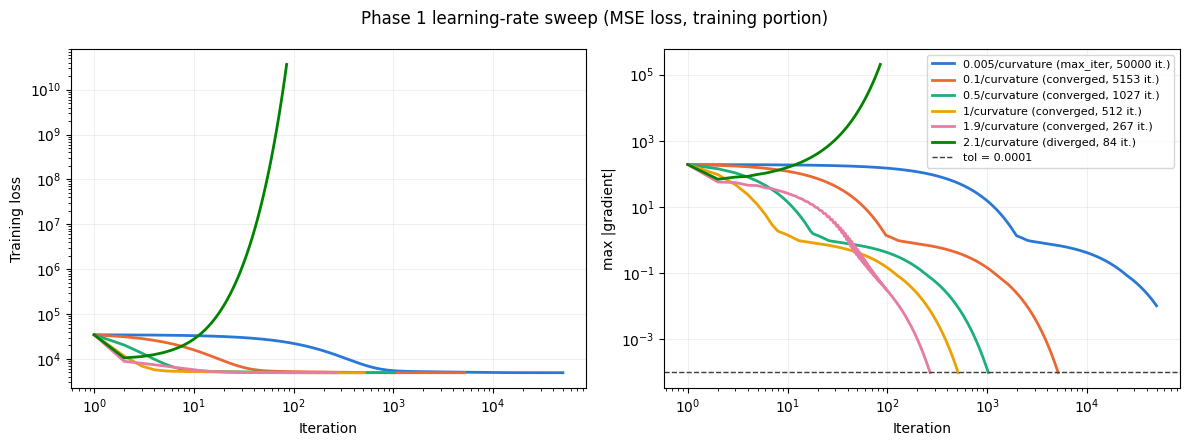

In [4]:
# Chosen representation (justified above): month dummies, no elapsed-time trend.
SEASONAL, USE_TREND = "mnth", False
features = Phase1Features(seasonal=SEASONAL, use_trend=USE_TREND).fit(train_df)
X_train, X_val = features.transform(train_df), features.transform(val_df)

lam_max = largest_curvature(X_train)
print(f"{X_train.shape[1] - 1} features + intercept; largest curvature = {lam_max:.4f}; "
      f"GD is stable only for learning rate < 2/curvature = {2 / lam_max:.4f}")

# Learning rates as multiples of 1/curvature, on both sides of the 2/curvature limit.
MULTIPLIERS = [0.005, 0.1, 0.5, 1.0, 1.9, 2.1]
sweep = {}
for multiplier in MULTIPLIERS:
    model = LinearRegressionGD(learning_rate=multiplier / lam_max, max_iter=MAX_ITER, tol=TOL)
    sweep[f"{multiplier:g}/curvature"] = model.fit(X_train, y_train)

sweep_table = pd.DataFrame([{
    "step": label,
    "learning_rate": result.learning_rate,
    "status": result.status,
    "iterations": result.iterations,
    "loss_ever_increased": bool(np.any(np.diff(result.loss_history) > 0)),
    "final_loss": result.loss_history[-1],
    "final_max_abs_gradient": result.grad_history[-1],
} for label, result in sweep.items()])
display(sweep_table)
plot_gd_runs(sweep, TOL, "Phase 1 learning-rate sweep (MSE loss, training portion)")
plt.show()

In [5]:
# Final Phase 1 model: the converged learning rate that needed the fewest updates.
converged = {label: r for label, r in sweep.items() if r.converged}
chosen_step = min(converged, key=lambda label: converged[label].iterations)
phase1_model = LinearRegressionGD(learning_rate=converged[chosen_step].learning_rate,
                                  max_iter=MAX_ITER, tol=TOL)
phase1_result = phase1_model.fit(X_train, y_train)
assert phase1_result.converged

phase1_metrics = {
    "train": regression_metrics(y_train, phase1_model.predict(X_train)),
    "validation": regression_metrics(y_val, phase1_model.predict(X_val)),
}
print(f"step {chosen_step}: learning rate {phase1_result.learning_rate:.5f}, "
      f"{phase1_result.iterations} updates, final max|gradient| "
      f"{phase1_result.grad_history[-1]:.2e}")
display(pd.DataFrame(phase1_metrics).T)

# Independent check (not used for training): the exact least-squares minimum.
# If GD had stalled, its predictions would differ noticeably from these.
exact_weights = np.linalg.lstsq(X_train, y_train, rcond=None)[0]
gap = np.max(np.abs(X_val @ phase1_result.weights - X_val @ exact_weights))
print(f"largest validation prediction gap between GD and exact minimum: {gap:.4f} bikes")

save_phase1_artifact(
    config.PHASE1_ARTIFACT, features, phase1_result,
    settings={"seed": seed, "max_iter": MAX_ITER, "tol": TOL,
              "step": chosen_step, "largest_curvature": lam_max},
    metrics=phase1_metrics,
)
print("Saved for Phase 2:", config.PHASE1_ARTIFACT.relative_to(config.ROOT))

step 1.9/curvature: learning rate 0.95507, 267 updates, final max|gradient| 9.95e-05


,r2,rmse
train,0.697032,99.337755
validation,0.682332,103.558191


largest validation prediction gap between GD and exact minimum: 0.0074 bikes
Saved for Phase 2: experiments\phase1\phase1_artifact.json


### Operator check: errors at busy hours

R² treats every hour alike, but the operator's costly failure is an empty station at a busy time. So for every fitted model we also report, on validation:
- errors per decile of demand (decile edges from training demand);
- the **top-decile shortfall**, i.e. the mean bikes missing in hours whose actual demand is above the training 90th percentile;
- the hour × day-type cells where the shortfall concentrates.

Grouping by *actual* demand answers the operator's question directly, but it flatters no model: the top bin also collects hours that were busy partly by chance, so any imperfect model looks under-predicted there. Grouping by *predicted* demand has no such selection effect. Under-prediction that persists there is a genuine bias.

training demand decile edges (bikes): [  9.  27.  61. 101. 144. 191. 249. 328. 452.]
top-decile shortfall (actual > 452 bikes): 176.6 bikes per hour
validation hours predicted below zero: 213

By ACTUAL demand decile:


,decile,hours,mean_actual,mean_predicted,mean_error,under_prediction_rate,mean_shortfall_bikes
0,1,216,4.80,-5.85,-10.65,0.55,33.69
1,2,206,16.98,44.39,27.41,0.36,17.60
2,3,225,43.03,76.28,33.25,0.37,16.26
3,4,212,82.01,134.64,52.63,0.29,10.31
4,5,206,121.77,172.15,50.38,0.28,8.92
5,6,230,167.03,223.64,56.62,0.26,7.55
6,7,230,218.32,253.07,34.75,0.30,11.80
7,8,226,285.91,296.87,10.96,0.42,22.82
8,9,206,383.59,325.27,-58.32,0.81,66.69
9,10,221,604.47,429.50,-174.96,0.96,176.64


By PREDICTED demand decile (no selection effect):


,decile,hours,mean_actual,mean_predicted,mean_error,under_prediction_rate,mean_shortfall_bikes
0,1,239,16.85,-43.92,-60.76,0.97,60.82
1,2,82,28.83,18.95,-9.88,0.55,14.76
2,3,135,40.93,43.69,2.76,0.38,14.01
3,4,181,57.44,84.50,27.06,0.31,7.41
4,5,202,82.53,122.56,40.02,0.24,9.13
5,6,230,136.55,166.60,30.05,0.34,13.78
6,7,300,197.97,221.14,23.17,0.33,25.12
7,8,390,280.92,287.96,7.03,0.39,42.52
8,9,307,375.87,380.07,4.20,0.50,57.83
9,10,112,605.42,509.50,-95.92,0.74,134.86


Hour x day-type cells with the largest shortfall:


,workingday,hr,hours,mean_actual,mean_predicted,mean_error,under_prediction_rate,mean_shortfall_bikes
12,0,12,21,436.9,284.0,-152.9,0.9,154.0
13,0,13,27,398.1,256.3,-141.8,0.9,144.8
11,0,11,25,348.2,215.1,-133.1,1.0,133.6
14,0,14,32,356.6,226.3,-130.3,0.9,131.6
15,0,15,29,365.4,252.4,-113.0,0.9,121.3
32,1,8,54,479.9,373.6,-106.2,0.7,118.0
41,1,17,76,532.6,464.8,-67.9,0.7,107.1
42,1,18,67,484.3,425.9,-58.5,0.6,97.0
16,0,16,34,381.5,313.1,-68.4,0.6,94.0
10,0,10,22,274.7,182.5,-92.2,1.0,93.6


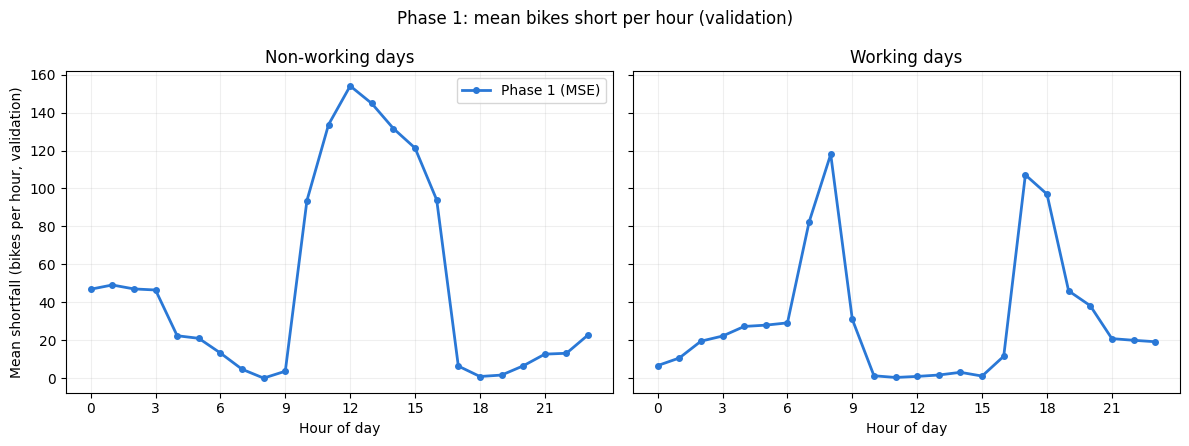

In [6]:
from src.operator_checks import (
    demand_decile_edges,
    errors_by_demand_decile,
    errors_by_hour_daytype,
    top_decile_shortfall,
    unscaled_coefficients,
)
from src.visualization import plot_shortfall_by_hour

# Operator check: are the busiest hours under-supplied? Decile edges come from
# training demand; error = predicted - actual, shortfall = bikes missing.
decile_edges = demand_decile_edges(y_train)
pred_phase1_val = phase1_model.predict(X_val)
print("training demand decile edges (bikes):", decile_edges[1:-1])
print(f"top-decile shortfall (actual > {decile_edges[-2]:.0f} bikes): "
      f"{top_decile_shortfall(y_val, pred_phase1_val, decile_edges):.1f} bikes per hour")
print("validation hours predicted below zero:", int(np.sum(pred_phase1_val < 0)))

print("\nBy ACTUAL demand decile:")
display(errors_by_demand_decile(y_val, pred_phase1_val, decile_edges).round(2))
print("By PREDICTED demand decile (no selection effect):")
display(errors_by_demand_decile(y_val, pred_phase1_val, decile_edges, bin_on="predicted").round(2))

phase1_hour_errors = errors_by_hour_daytype(val_df, y_val, pred_phase1_val)
print("Hour x day-type cells with the largest shortfall:")
display(phase1_hour_errors.sort_values("mean_shortfall_bikes", ascending=False).head(10).round(1))
plot_shortfall_by_hour({"Phase 1 (MSE)": phase1_hour_errors},
                       "Phase 1: mean bikes short per hour (validation)")
plt.show()

### Outcome

_DRAFT — team to review._

1. **Fit: as expected.**
   - Validation R² 0.6823 (RMSE 103.6 bikes), training R² 0.6970: inside our range, with a small gap (0.015). The model underfits rather than overfits.
   - It misses the busiest hours. Hours above 452 bikes are under-predicted by 176.6 bikes on average, and even the hours the model itself predicts busiest are, on average, 95.9 bikes too low: an additive model cannot reach the peaks.
   - The largest misses are weekend 11:00–15:00 (121–154 bikes short) and working-day 08:00 (118 short). 213 validation hours are predicted below zero.
2. **Learning rate: as expected.**
   - λ_max = 1.9894, so the limit is 1.0053. 2.1/λ_max diverged after 84 updates.
   - 0.005/λ_max hit the 50,000-update cap with max|gradient| 0.0104: its loss curve looked flat, but it had not converged.
   - Every rate from 0.1 to 1.9/λ_max converged to the same loss. We chose 1.9/λ_max (0.955, 267 updates). Its predictions are within 0.0074 bikes of the exact least-squares solution.

**What surprised us.** The elapsed-time trend from `dteday` added only 0.0005 R² but raised the condition number from 56 to 8,084, so GD needed 36,407 updates instead of 512.

**Handed to Phase 2:** the 48 weights (intercept + 47 features), learning rate 0.955, 267 updates, the feature names in order and the fitted encoder and scaler (`experiments/phase1/phase1_artifact.json`).

## Phase 1 bonus — asymmetric cost (optional, +5%)

This section is separate from the chain. It reads the Phase 1 artifact but writes nothing that Phase 2 or the submission file reads (Check 3 below proves the artifact is unchanged). It uses the same split (seed 36954), the same 47 features and fitted scaler, and the same `LinearRegressionGD` loop. Only the loss/gradient hook is replaced (`AsymmetricLinearRegressionGD` in `src/bonus_asymmetric.py`). This loss is not quadratic (each row's weight depends on the sign of its residual), so it has no fixed $H = X^\top X/n$: the bonus evaluates the explicit gradient $X^\top(c \odot r)/n$ at every update instead of Phase 1's precomputed form.

**Our reading of "under-predicting costs 3× as much".** We keep the squared error and weight under-predictions by $k = 3$:

$$\ell(r) = \tfrac{1}{2}\,c(r)\,r^2,\qquad r = \hat y - y,\qquad c(r) = \begin{cases} k & r < 0 \text{ (under-prediction)}\\ 1 & r \ge 0 \end{cases}$$

Why this reading:
- The brief asks us to minimize the loss *instead of MSE*, derive *its gradient*, and compare against *our MSE model*. Keeping the quadratic shape changes exactly one thing, the asymmetry, so the shift we measure is caused by the asymmetry alone.
- The loss is differentiable everywhere, so our Phase 1 GD and its gradient-based stopping rule work unchanged.

The other reading, a cost linear in the number of bikes (pinball loss, as in the newsvendor problem, whose optimum is the 75th percentile), is arguably closer to how lost rentals add up. But it has no gradient at $r = 0$, and its slope never shrinks toward zero, so fixed-step GD with our stopping rule could not converge on it. Our assumption is stated openly: a large shortfall is penalized more than in proportion to its size.

**Gradient derivation.**

$$L_k(w) = \frac{1}{2n}\sum_{i=1}^{n} c_i\, r_i^2,\qquad r_i = x_i^\top w - y_i$$

1. *Derivative of one row's loss.* For $r < 0$, $\ell(r) = \tfrac{k}{2}r^2$, so $\ell'(r) = k\,r$. For $r > 0$, $\ell'(r) = r$. At $r = 0$ both one-sided difference quotients $(\ell(h) - \ell(0))/h = \tfrac{1}{2}c\,h$ tend to $0$, so $\ell'(0) = 0$. Hence $\ell'(r) = c(r)\,r$ everywhere, and it is continuous.
2. *Chain rule.* With $\partial r_i/\partial w = x_i$:
$$\nabla L_k(w) = \frac{1}{n}\sum_{i=1}^{n} c_i\, r_i\, x_i = \frac{1}{n}X^\top (c \odot r)$$
3. *Comparison with MSE.* Since $c(r)\,r = r + (k-1)\min(r, 0)$:
$$\nabla L_k = \underbrace{\tfrac{1}{n}X^\top r}_{\text{MSE gradient}} + \tfrac{k-1}{n}X^\top \min(r, 0)$$
This is the MSE gradient plus an extra push that comes only from under-predicted rows. With $k = 1$ it is exactly Phase 1.
4. *Convexity.* $\ell'$ is continuous and non-decreasing (slope $k$ on the left of 0, slope 1 on the right), so $\ell$ is convex. $L_k$ is an average of convex functions of $w$, so any point with zero gradient is the global minimum.
5. *Step size.* $|\ell'(a) - \ell'(b)| \le k\,|a - b|$, so the gradient of $L_k$ changes at most $k$ times as fast as in the MSE case, and GD is guaranteed to converge for learning rates below $2/(k\,\lambda_{max})$. The safe limit is $k$ times smaller than for MSE.
6. *What the minimum means.* The intercept row of $X^\top(c \odot r) = 0$ gives $\sum_{r_i>0} r_i = k\sum_{r_i<0}|r_i|$: on training, total over-prediction equals 3× total under-prediction. For an intercept-only model the minimizer is the 0.75 *expectile* ($\tau = k/(k+1)$), an asymmetric mean, not the 75th percentile.

### Expectation (bonus)

_Reconstructed from pre-run design notes (14 Oct), written after the run. This cell was empty when the bonus was first run; it is not backdated._

1. **Loss.** We minimize the asymmetric squared loss (under-predictions weighted 3×). Its minimizer is an asymmetric mean (the 0.75 expectile), not the mean, so predictions should **shift upward**, and mostly where demand varies most (commute peaks), not uniformly.
2. **Accuracy vs cost.** Validation R² should fall and RMSE rise, because both score the MSE objective. The asymmetric cost on validation should fall.
3. **Step size.** The loss's curvature can be up to 3× larger than for MSE, so the Phase 1 learning rate may diverge; the safe step shrinks by about 3×.

In [7]:
from src.bonus_asymmetric import (
    AsymmetricLinearRegressionGD,
    finite_difference_gradient,
    prediction_summary,
    residual_structure,
    shift_by_hour,
)

UNDER_COST = 3.0  # k: under-predicting costs 3x as much as over-predicting

# Read Phase 1's artifact (read-only) and fingerprint it so we can prove later
# that the bonus did not change what Phase 2 consumes.
artifact_hash_before = hashlib.sha256(config.PHASE1_ARTIFACT.read_bytes()).hexdigest()
phase1 = load_phase1_artifact(config.PHASE1_ARTIFACT)
bonus_features = Phase1Features.from_dict(phase1["features"])
Xb_train, Xb_val = bonus_features.transform(train_df), bonus_features.transform(val_df)
w_phase1 = phase1["weights"]
assert np.array_equal(Xb_train, X_train), "bonus must use exactly the Phase 1 features"

# Check 1: analytic gradient X^T (c * r) / n against central finite differences.
checker = AsymmetricLinearRegressionGD(under_cost=UNDER_COST)
for name, w in (("at Phase 1 weights", w_phase1), ("at zero weights", np.zeros_like(w_phase1))):
    analytic = checker.loss_and_gradient(Xb_train, y_train, w)[1]
    numeric = finite_difference_gradient(checker, Xb_train, y_train, w)
    error = np.max(np.abs(analytic - numeric)) / np.max(np.abs(analytic))
    print(f"Check 1 {name}: largest relative gradient error = {error:.1e}")

# Check 2: with k = 1 the bonus model is the Phase 1 model, so from the same
# start and settings it must reach the Phase 1 weights. Phase 1's loop uses the
# precomputed H w - b and the bonus the explicit gradient, so the two agree up
# to floating-point rounding rather than bit for bit.
k_one = AsymmetricLinearRegressionGD(
    under_cost=1.0, learning_rate=phase1["learning_rate"],
    max_iter=phase1["settings"]["max_iter"], tol=phase1["settings"]["tol"],
).fit(Xb_train, y_train)
weight_gap = np.max(np.abs(k_one.weights - w_phase1))
print(f"Check 2: k = 1 reaches the Phase 1 weights: largest difference {weight_gap:.1e}; "
      f"{k_one.iterations} updates vs Phase 1's {phase1['iterations']}")
assert weight_gap < 1e-8

Check 1 at Phase 1 weights: largest relative gradient error = 1.9e-10
Check 1 at zero weights: largest relative gradient error = 2.7e-10
Check 2: k = 1 reaches the Phase 1 weights: largest difference 1.4e-13; 267 updates vs Phase 1's 267


**Learning rate, start and stopping rule.**
- *Stopping rule and tol:* identical to Phase 1.
- *Start:* the Phase 1 weights. The feature space is the same, and by convexity (step 4) the start does not change the answer.
- *Learning rate:* step 5 says the safe limit shrinks by $k$. We run the Phase 1 learning rate unchanged, and the Phase 1 learning rate divided by $k$. The second is 0.955/3 = 0.318, below the guaranteed limit $2/(3\lambda_{max}) = 0.335$.

,step,learning_rate,status,iterations,loss_ever_increased,final_loss,final_max_abs_gradient
0,Phase 1 step,0.955069,diverged,12,True,4.269998e+10,304168.79591
1,Phase 1 step / k,0.318356,converged,388,False,8.535525e+03,0.00010


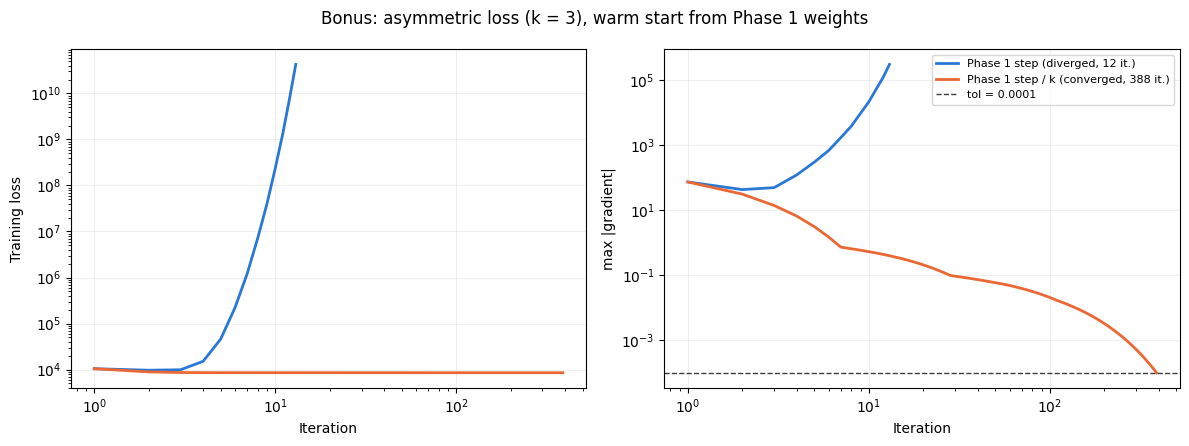

In [8]:
# Learning rate: the Phase 1 step, and the Phase 1 step divided by k (the
# gradient can change up to k times faster, so the safe step shrinks by k).
# Both start from the Phase 1 weights.
phase1_step = phase1["learning_rate"]
bonus_runs = {}
for label, step in (("Phase 1 step", phase1_step), ("Phase 1 step / k", phase1_step / UNDER_COST)):
    model = AsymmetricLinearRegressionGD(under_cost=UNDER_COST, learning_rate=step,
                                         max_iter=MAX_ITER, tol=TOL)
    bonus_runs[label] = model.fit(Xb_train, y_train, init_weights=w_phase1)

display(pd.DataFrame([{
    "step": label,
    "learning_rate": result.learning_rate,
    "status": result.status,
    "iterations": result.iterations,
    "loss_ever_increased": bool(np.any(np.diff(result.loss_history) > 0)),
    "final_loss": result.loss_history[-1],
    "final_max_abs_gradient": result.grad_history[-1],
} for label, result in bonus_runs.items()]))
plot_gd_runs(bonus_runs, TOL, "Bonus: asymmetric loss (k = 3), warm start from Phase 1 weights")
plt.show()

asym_result = bonus_runs["Phase 1 step / k"]
assert asym_result.converged

,MSE model (Phase 1),Asymmetric model (k=3),change
r2,0.682332,0.605877,-0.076454
rmse,103.558191,115.348815,11.790624
asymmetric_cost,11144.979334,9343.449781,-1801.529553
mean_prediction,196.379504,238.958127,42.578624
under_prediction_rate,0.458219,0.321855,-0.136364
mean_shortfall_bikes,37.174786,21.170793,-16.003992
mean_surplus_bikes,39.550157,66.124789,26.574631


shift per hour (bikes): mean 42.6, median 39.2, min -2.7, max 108.7; share of hours shifted down: 0.2%


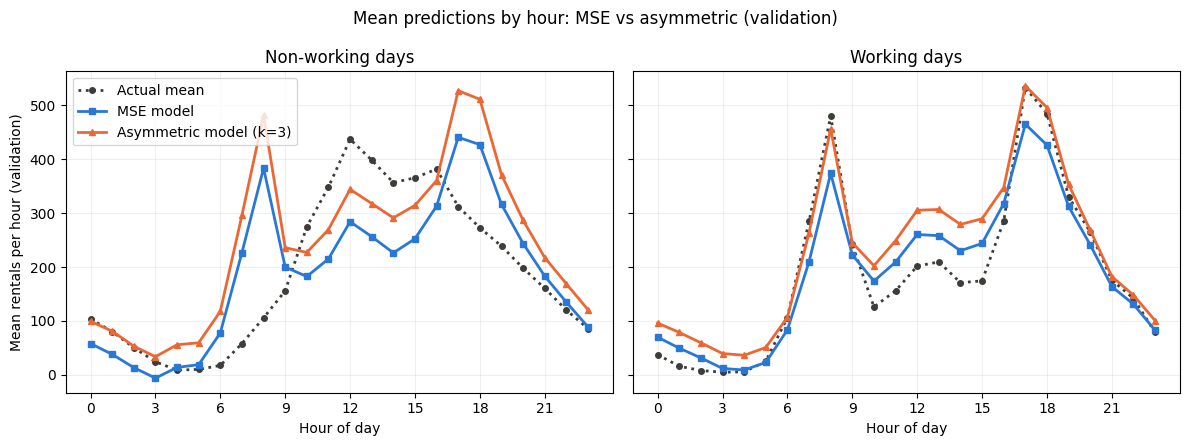

In [9]:
# How the fitted predictions shift (validation set, same rows for both models).
pred_mse = Xb_val @ w_phase1
pred_asym = Xb_val @ asym_result.weights

comparison = pd.DataFrame({
    "MSE model (Phase 1)": prediction_summary(y_val, pred_mse, UNDER_COST),
    "Asymmetric model (k=3)": prediction_summary(y_val, pred_asym, UNDER_COST),
})
comparison["change"] = comparison.iloc[:, 1] - comparison.iloc[:, 0]
display(comparison)

shift = pred_asym - pred_mse
print(f"shift per hour (bikes): mean {shift.mean():.1f}, median {np.median(shift):.1f}, "
      f"min {shift.min():.1f}, max {shift.max():.1f}; "
      f"share of hours shifted down: {np.mean(shift < 0):.1%}")

hour_table = shift_by_hour(val_df, y_val, pred_mse, pred_asym)
plot_shift_by_hour(hour_table, "Mean predictions by hour: MSE vs asymmetric (validation)")
plt.show()

config.BONUS_DIR.mkdir(parents=True, exist_ok=True)
comparison.to_csv(config.BONUS_DIR / "validation_comparison.csv")
hour_table.to_csv(config.BONUS_DIR / "shift_by_hour.csv", index=False)

In [10]:
# Underfitting vs demand variability. Phase 1 has no hour x day-type terms, so
# its residuals in each hour x day-type cell need not average to zero.
train_residual = Xb_train @ w_phase1 - y_train
cell_table, shares = residual_structure(train_df, train_residual)
print(f"Phase 1 training residual variance: {shares['between_cell_share']:.1%} between "
      f"hour x day-type cells (systematic misfit), {shares['within_cell_share']:.1%} within cells")

# Where does the shift land? Cells with a positive mean residual are ones the
# MSE model already over-predicts; raising them further only adds cost.
val_cells = (val_df[["workingday", "hr"]].assign(shift=shift)
             .merge(cell_table, on=["workingday", "hr"], how="left"))
already_over = val_cells["mean_residual"] > 0
print(f"validation hours in already over-predicted cells: {already_over.mean():.1%}, "
      f"receiving {val_cells['shift'][already_over].sum() / val_cells['shift'].sum():.1%} "
      f"of the total upward shift")
print(f"mean shift there: {val_cells['shift'][already_over].mean():.1f} bikes, "
      f"elsewhere: {val_cells['shift'][~already_over].mean():.1f} bikes")

cells = hour_table.merge(cell_table, on=["workingday", "hr"])
print(f"correlation across the 48 cells: shift vs within-cell residual SD = "
      f"{cells['shift'].corr(cells['within_sd']):.2f}, "
      f"shift vs cell mean residual = {cells['shift'].corr(cells['mean_residual']):.2f}")
cells.sort_values("shift", ascending=False).head(8).round(1)

Phase 1 training residual variance: 44.4% between hour x day-type cells (systematic misfit), 55.6% within cells
validation hours in already over-predicted cells: 50.5%, receiving 48.6% of the total upward shift
mean shift there: 41.0 bikes, elsewhere: 44.2 bikes
correlation across the 48 cells: shift vs within-cell residual SD = 0.67, shift vs cell mean residual = 0.14


,workingday,hr,actual,pred_mse,pred_asym,shift,mean_residual,within_sd
8,0,8,105.8,383.3,481.6,98.3,252.4,79.2
17,0,17,312.0,440.4,526.7,86.3,119.0,107.4
18,0,18,272.8,426.8,510.9,84.0,134.6,94.7
32,1,8,479.9,373.6,456.1,82.5,-107.5,122.4
41,1,17,532.6,464.8,535.6,70.8,-60.8,150.9
42,1,18,484.3,425.9,495.5,69.7,-62.4,152.4
7,0,7,58.1,226.7,295.8,69.0,161.1,60.5
14,0,14,356.6,226.3,291.1,64.9,-137.8,100.9


MSE model: top-decile shortfall 176.6 bikes per hour
Asymmetric model: top-decile shortfall 112.1 bikes per hour


,decile,mean_actual,mean_shift,under_rate_mse,under_rate_asym,shortfall_mse,shortfall_asym
0,1,4.80,29.49,0.55,0.38,33.69,22.74
1,2,16.98,33.28,0.36,0.26,17.60,10.72
2,3,43.03,34.13,0.37,0.25,16.26,8.62
3,4,82.01,38.19,0.29,0.17,10.31,4.42
4,5,121.77,36.96,0.28,0.15,8.92,4.31
5,6,167.03,41.01,0.26,0.12,7.55,3.01
6,7,218.32,42.62,0.30,0.17,11.80,4.18
7,8,285.91,47.52,0.42,0.27,22.82,9.15
8,9,383.59,52.35,0.81,0.57,66.69,32.62
9,10,604.47,69.51,0.96,0.88,176.64,112.13


,mse,asym,change
hr=8,321.9,379.1,57.2
hr=18,356.4,400.6,44.2
hr=17,384.0,427.5,43.5
intercept,-76.5,-39.6,36.9
hr=7,165.3,193.7,28.3
hr=14,159.0,183.7,24.7
hr=13,172.1,194.8,22.7
weekday=5,16.0,-5.8,-21.8
hr=15,169.5,189.2,19.6
hr=12,178.6,196.9,18.2


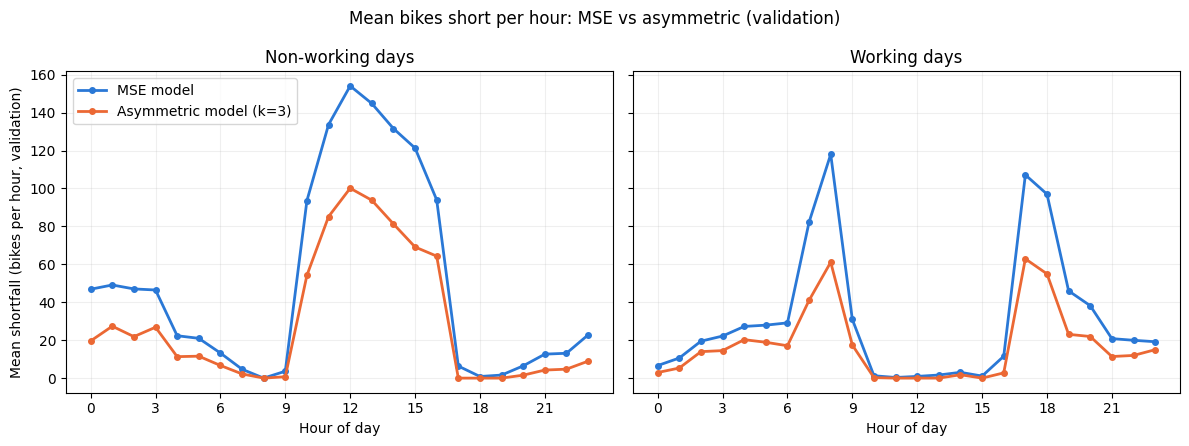

In [11]:
# Operator check for the bonus: does k = 3 fix the busiest hours, or lift everything?
for label, pred in (("MSE model", pred_mse), ("Asymmetric model", pred_asym)):
    print(f"{label}: top-decile shortfall "
          f"{top_decile_shortfall(y_val, pred, decile_edges):.1f} bikes per hour")

by_decile_mse = errors_by_demand_decile(y_val, pred_mse, decile_edges)
by_decile_asym = errors_by_demand_decile(y_val, pred_asym, decile_edges)
display(pd.DataFrame({
    "decile": by_decile_mse["decile"],
    "mean_actual": by_decile_mse["mean_actual"],
    "mean_shift": by_decile_asym["mean_predicted"] - by_decile_mse["mean_predicted"],
    "under_rate_mse": by_decile_mse["under_prediction_rate"],
    "under_rate_asym": by_decile_asym["under_prediction_rate"],
    "shortfall_mse": by_decile_mse["mean_shortfall_bikes"],
    "shortfall_asym": by_decile_asym["mean_shortfall_bikes"],
}).round(2))

# Which coefficients moved? In original units: a dummy's coefficient is the
# bikes it adds relative to its reference level (hr=0, Sunday, January, clear).
names, mean, std = bonus_features.feature_names, bonus_features.mean, bonus_features.std
coefficients = pd.DataFrame({
    "mse": unscaled_coefficients(w_phase1, names, mean, std),
    "asym": unscaled_coefficients(asym_result.weights, names, mean, std),
})
coefficients["change"] = coefficients["asym"] - coefficients["mse"]
largest_moves = coefficients["change"].abs().sort_values(ascending=False).index[:12]
display(coefficients.loc[largest_moves].round(1))

plot_shortfall_by_hour({
    "MSE model": errors_by_hour_daytype(val_df, y_val, pred_mse),
    "Asymmetric model (k=3)": errors_by_hour_daytype(val_df, y_val, pred_asym),
}, "Mean bikes short per hour: MSE vs asymmetric (validation)")
plt.show()

In [12]:
# Check 3: the bonus left Phase 1's artifact (what Phase 2 consumes) untouched.
assert hashlib.sha256(config.PHASE1_ARTIFACT.read_bytes()).hexdigest() == artifact_hash_before
assert np.array_equal(load_phase1_artifact(config.PHASE1_ARTIFACT)["weights"],
                      phase1_result.weights)
print("Check 3: Phase 1 artifact and weights unchanged by the bonus")

Check 3: Phase 1 artifact and weights unchanged by the bonus


### Outcome (bonus)

_DRAFT — team to review._

**Checks.** All three passed:
- the analytic gradient matched finite differences (relative error ≤ 2.7·10⁻¹⁰);
- k = 1 reached the Phase 1 weights (largest difference 1.4·10⁻¹³, same 267 updates);
- the Phase 1 artifact was unchanged.

1. **Upward shift: right in direction, wrong in where it goes.**
   - Predictions rose 42.6 bikes/hour on average (median 39.2); only 0.2% of hours went down.
   - The rise is larger in the busiest decile (+69.5) than in the quietest (+29.5), but it is mostly a broad lift. The intercept alone rose 36.9 bikes, which applies to every hour; the 08:00, 17:00 and 18:00 dummies rose by 57.2, 43.5 and 44.2.
   - The reason is Phase 1's underfitting. 44.4% of its training residual variance lies *between* hour × day-type cells. 50.5% of validation hours sit in cells it already over-predicts, and they still received 48.6% of the upward shift. Example: weekend 08:00 was predicted at 383 against an actual mean of 106, and was raised by another 98.
   - Under-predicted hours fell from 45.8% to 32.2%, not to 25%. That is consistent with an asymmetric mean, not the 75th percentile.
2. **Accuracy vs cost: as expected.**
   - R² 0.682 → 0.606, RMSE 103.6 → 115.3. Asymmetric cost 11,145 → 9,343 (−16.2%).
   - For the operator: bikes short per hour 37.2 → 21.2, idle bikes 39.6 → 66.1. Top-decile shortfall 176.6 → 112.1, but 88% of those hours are still under-predicted.
3. **Step size: as expected.** Phase 1's rate (0.955) diverged within 12 updates. Divided by 3 (0.318, below the guaranteed limit 0.335), it converged in 388 updates without the loss ever rising.

**Lesson.** The asymmetric loss moves errors toward surplus, but it cannot create structure the features lack. With Phase 1's features, about half of the extra bikes go to hours that were already over-stocked. The follow-up after Phase 2 tests the same loss on better features.

## Phase 2 — Polynomial Regression

### Which interactions? Residual diagnosis of Phase 1 (training rows only)

Phase 1 has main effects only, so each training residual $e = y - \hat y$ contains whatever the main effects cannot express. For example, if the 08:00 level depends on whether it is a working day, Phase 1's 08:00 residuals will be positive on working days and negative on the others.

For each candidate combination we group the 8,708 training residuals into cells and measure:
- **between share**: the share of Phase 1's residual variance that the cell means explain, i.e. how much of what Phase 1 misses this combination could recover. Overlapping combinations (e.g. month and temperature) are not additive.
- **adjusted share**: the between share corrected for the number of cells, like adjusted R², so a combination with many cells cannot win by size alone.
- **cell support**: rows per cell, and how many cells have fewer than 30 rows (a 30-row mean is still uncertain by about ±18 bikes).

Continuous columns are cut into equal-count bins on training rows: 10 bins for `temp` alone, 5 bins inside products. Validation rows are not used. Phase 1's residuals average to zero within every hour (checked below), so an hour × X cell measures only the interaction.

mean training residual 0.0000; largest |mean residual| of any single hour 0.0028
holiday dates in the training portion: 13


,combination,cells,between_share,adjusted_share,min_cell_rows,median_cell_rows,cells_under_30,rows_in_sparse_cells
0,hour x weekday,168,0.4498,0.4390,41,52.0,0,0
1,hour x workingday,48,0.4440,0.4410,106,177.0,0,0
2,hour x month,288,0.1297,0.1000,21,30.0,105,2889
3,temp bins (5) x hour,120,0.1124,0.1001,18,70.5,4,90
4,hour x yr,48,0.1068,0.1019,163,182.0,0,0
5,hour x season,96,0.0939,0.0839,77,91.0,0,0
6,temp bins (5) x hum bins (5),25,0.0387,0.0361,70,352.0,0,0
7,hum bins (5) x hour,120,0.0316,0.0181,10,72.5,13,260
8,hour x weathersit,72,0.0289,0.0209,21,94.0,13,323
9,windspeed bins (5) x hour,120,0.0130,-0.0007,29,73.5,1,29


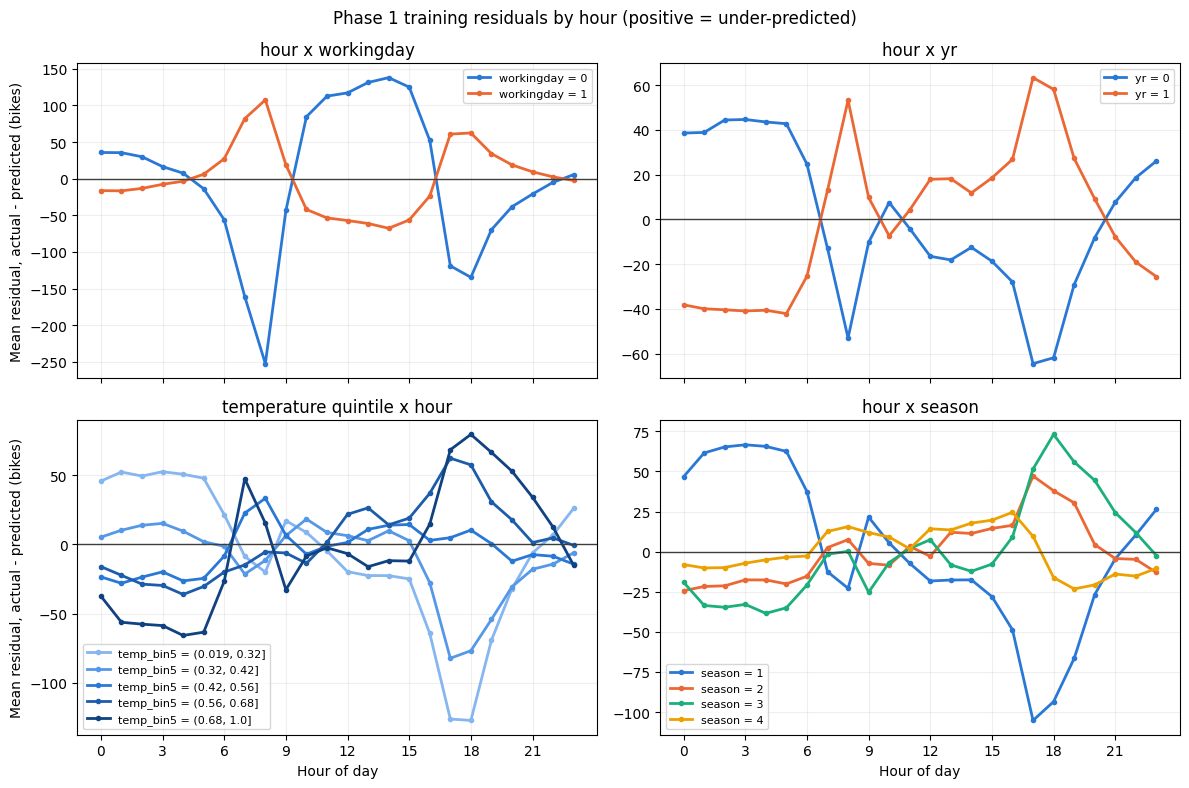

In [13]:
from src.phase2_polynomial import residual_cell_means, residual_diagnosis
from src.visualization import plot_residual_profiles

# Phase 2 starts from Phase 1's artifact: its features, scaler and weights.
phase1_artifact = load_phase1_artifact(config.PHASE1_ARTIFACT)
phase1_features = Phase1Features.from_dict(phase1_artifact["features"])
phase1_residual = y_train - phase1_features.transform(train_df) @ phase1_artifact["weights"]
hour_means = pd.Series(phase1_residual).groupby(train_df["hr"].to_numpy()).mean()
print(f"mean training residual {phase1_residual.mean():.4f}; "
      f"largest |mean residual| of any single hour {hour_means.abs().max():.4f}")
print("holiday dates in the training portion:",
      train_df.loc[train_df["holiday"] == 1, "dteday"].nunique())

diagnosis = residual_diagnosis(train_df, phase1_residual)
config.PHASE2_DIR.mkdir(parents=True, exist_ok=True)
diagnosis.to_csv(config.PHASE2_DIR / "residual_diagnosis.csv", index=False)
display(diagnosis.round(4))

panels = [
    ("hour x workingday", residual_cell_means(train_df, phase1_residual, ["hr", "workingday"]),
     "workingday", False),
    ("hour x yr", residual_cell_means(train_df, phase1_residual, ["hr", "yr"]), "yr", False),
    ("temperature quintile x hour",
     residual_cell_means(train_df, phase1_residual, ["temp_bin5", "hr"]), "temp_bin5", True),
    ("hour x season", residual_cell_means(train_df, phase1_residual, ["hr", "season"]),
     "season", False),
]
plot_residual_profiles(panels, "Phase 1 training residuals by hour (positive = under-predicted)")
plt.show()

### Re-ranking after the confirmed groups

The Step A shares overlap (month, season and temperature all follow the yearly cycle), so we re-rank the remaining candidates on what is left *after* the confirmed groups:
1. remove the hour × workingday group means from Phase 1's training residuals;
2. remove hour × workingday and hour × yr together (least squares on both groups' indicators; for one group this is just its group means).

For a continuous candidate (hour × temp, temp × hum, temp²) the share is the R² of the remaining residuals regressed on its columns; for a group candidate this R² is exactly the between-group share of Step A. Training rows only.

In [14]:
from src.phase2_polynomial import (
    RERANK_CANDIDATES,
    diagnosis_frame,
    project_out,
    remove_group_means,
    rerank,
)

frame = diagnosis_frame(train_df)
phase1_total = np.sum(phase1_residual ** 2)
stages = {
    "after hour x workingday":
        remove_group_means(phase1_residual, frame, [["hr", "workingday"]]),
    "after hour x workingday + hour x yr":
        remove_group_means(phase1_residual, frame, [["hr", "workingday"], ["hr", "yr"]]),
}
for stage, residual in stages.items():
    remaining = np.sum((residual - residual.mean()) ** 2) / phase1_total
    print(f"{stage}: {remaining:.1%} of Phase 1's residual variance remains")
    table = rerank(residual, frame)
    table.insert(3, "share_of_phase1_variance", table["share"] * remaining)
    display(table.round(4))

# Season and temperature both follow the yearly cycle: what does each add after the other?
after_confirmed = stages["after hour x workingday + hour x yr"]
overlap_rows = []
for first, second in [("hour x season", "hour x temp"),
                      ("hour x temp", "hour x season"),
                      ("hour x season", "hour x workingday x temp"),
                      ("hour x season", "hour x workingday x season")]:
    residual = project_out(after_confirmed, frame, RERANK_CANDIDATES[first])
    remaining = np.sum((residual - residual.mean()) ** 2) / phase1_total
    added = rerank(residual, frame, {second: RERANK_CANDIDATES[second]}).iloc[0]
    overlap_rows.append({
        "already in": first,
        "candidate": second,
        "adds_share_of_phase1_variance": added["share"] * remaining,
        "adjusted_share_of_remaining": added["adjusted_share"],
    })
display(pd.DataFrame(overlap_rows).round(4))

after hour x workingday: 55.6% of Phase 1's residual variance remains


,candidate,columns,share,share_of_phase1_variance,adjusted_share,min_cell_rows,cells_under_30,rows_in_sparse_cells
0,hour x workingday x yr,96,0.2431,0.1351,0.2347,49.0,0.0,0.0
1,hour x workingday x temp,96,0.2081,0.1157,0.1994,106.0,0.0,0.0
2,hour x workingday x season,192,0.2103,0.1169,0.1926,21.0,59.0,1613.0
3,hour x temp,48,0.1742,0.0968,0.1697,340.0,0.0,0.0
4,hour x season,96,0.1696,0.0943,0.1604,77.0,0.0,0.0
5,hour x weathersit,72,0.0430,0.0239,0.0351,21.0,13.0,323.0
6,temp x hum,4,0.0340,0.0189,0.0337,NaN,NaN,NaN
7,hour-block x weathersit,15,0.0332,0.0185,0.0317,116.0,0.0,0.0
8,temp^2,3,0.0034,0.0019,0.0031,NaN,NaN,NaN


after hour x workingday + hour x yr: 44.9% of Phase 1's residual variance remains


,candidate,columns,share,share_of_phase1_variance,adjusted_share,min_cell_rows,cells_under_30,rows_in_sparse_cells
0,hour x workingday x season,192,0.2651,0.1190,0.2486,21.0,59.0,1613.0
1,hour x workingday x temp,96,0.2284,0.1026,0.2199,106.0,0.0,0.0
2,hour x season,96,0.2141,0.0962,0.2055,77.0,0.0,0.0
3,hour x temp,48,0.1866,0.0838,0.1822,340.0,0.0,0.0
4,hour x workingday x yr,96,0.0629,0.0282,0.0525,49.0,0.0,0.0
5,hour x weathersit,72,0.0498,0.0224,0.0420,21.0,13.0,323.0
6,hour-block x weathersit,15,0.0388,0.0174,0.0373,116.0,0.0,0.0
7,temp x hum,4,0.0326,0.0147,0.0323,NaN,NaN,NaN
8,temp^2,3,0.0032,0.0014,0.0029,NaN,NaN,NaN


,already in,candidate,adds_share_of_phase1_variance,adjusted_share_of_remaining
0,hour x season,hour x temp,0.0061,0.0120
1,hour x temp,hour x season,0.0283,0.0674
2,hour x season,hour x workingday x temp,0.0246,0.0595
3,hour x season,hour x workingday x season,0.0229,0.0439


### Phase 2 design: which terms, how they are formed, how they are fitted

**Groups, in the order they are added** (evidence: the two tables above).

| Degree | Group | Columns | Why |
|---|---|---:|---|
| 2 | hour × workingday | 23 | Largest Step A share (0.444); the weekday/weekend daily shape. |
| 2 | hour × yr | 23 | 0.107 in Step A; 2012 peaks are higher, not just shifted. |
| 2 | hour × season | 69 | Best yearly-cycle candidate after the confirmed groups (adjusted 0.2055 vs hour × temp 0.1822). After it, hour × temp adds only 0.0061 of Phase 1's variance, while season still adds 0.0283 after temp. No sparse cells (min 77 rows). Month was rejected in Step A (105 sparse cells). |
| 2 | hour-block × weathersit | 8 | Day parts: night 0–5, morning 6–9, midday 10–15, evening 16–19, late 20–23. Adjusted 0.0373 with 15 cells and none sparse, vs full hour × weathersit 0.0420 with 72 cells, 13 of them sparse. |
| 2 | temp × hum | 1 | Adjusted 0.0323 for a single extra column (temp and hum are already in Phase 1). |
| 3 | hour × workingday × yr | 24 | Still 0.0525 adjusted after both confirmed groups: the weekday peaks grow more from 2011 to 2012 than the rest of the day. Includes workingday × yr. Min 117 rows per term. |
| 3 | hour × workingday × temp | 47 | Adds 0.0246 after hour × season with no sparse cells, more than hour × workingday × season (0.0229, 59 sparse cells). Includes hour × temp and workingday × temp, so the model stays hierarchical. |

Rejected after re-ranking: hour × temp as a separate degree-2 group (overlaps season; it enters only inside the degree-3 group), full hour × weathersit (sparse), temp² (adjusted 0.0029).

**How terms are formed.**
- Explicit term lists only (`group_terms` in `src/phase2_polynomial.py`). No product of two levels of one column (always 0), no square of a 0/1 column, and reference levels are skipped, so no term duplicates a Phase 1 column.
- `workingday` re-enters only through its interactions; its main effect is already carried by `weekday` + `holiday`.
- A product is built from raw values. The hour (or hour-block) indicator is used as 0/1; every other factor is first centered at its training mean (e.g. `hr=8 * (workingday − its training mean)`). Centering does not change which models the columns can express, but it makes the products much less correlated with the hour indicators: the full design's condition number with and without centering is shown below.
- Phase 1's 47 columns keep Phase 1's fitted scaler unchanged. Each new column is standardized with its own training mean and standard deviation.

**How it is fitted.**
- Degree = interaction order. Degree 1 is Phase 1 exactly; degree 2 adds the five pair groups; degree 3 adds the two triple groups. Groups are added one at a time and every step is scored, so each group's contribution is a number.
- Every step starts from Phase 1's weights in their own columns and 0 for every new column (the brief's warm start). Before training we assert that this starting model reproduces Phase 1's predictions.
- Same GD code, loss, stopping rule (max |gradient| < 1e-4, cap 50,000) and learning-rate rule as Phase 1: the same multiple of 1/λ_max, with λ_max recomputed for each expanded matrix.
- Degree is chosen on validation R²; the top-decile shortfall (by actual and by predicted demand) is reported next to it for the operator.

In [15]:
from src.phase2_polynomial import PHASE2_GROUPS, Phase2Features

# Design checks on training rows only (nothing is fitted here).
phase1_train_pred = phase1_features.transform(train_df) @ phase1_artifact["weights"]
design_rows, groups_so_far = [], []
for group in [None, *PHASE2_GROUPS]:
    if group:
        groups_so_far.append(group)
    candidate = Phase2Features(phase1_features, groups_so_far).fit(train_df)
    X_tr = candidate.transform(train_df)
    eigenvalues = np.linalg.eigvalsh(X_tr.T @ X_tr / len(X_tr))
    start = X_tr @ candidate.warm_start(phase1_artifact["weights"])
    design_rows.append({
        "added group": group or "(Phase 1)",
        "degree": PHASE2_GROUPS.get(group, 1),
        "columns": X_tr.shape[1],
        "rank": np.linalg.matrix_rank(X_tr),
        "condition_number": eigenvalues[-1] / eigenvalues[0],
        "warm_start_max_prediction_change": np.max(np.abs(start - phase1_train_pred)),
    })
display(pd.DataFrame(design_rows))

uncentered = Phase2Features(phase1_features, list(PHASE2_GROUPS), center_factors=False).fit(train_df)
X_unc = uncentered.transform(train_df)
eig_unc = np.linalg.eigvalsh(X_unc.T @ X_unc / len(X_unc))
print(f"full design condition number: {design_rows[-1]['condition_number']:.0f} with centering, "
      f"{eig_unc[-1] / eig_unc[0]:.0f} without")

print("Training rows supporting each new term (non-zero before centering):")
display(candidate.term_support(train_df).groupby("group", sort=False)["support_rows"]
        .agg(terms="count", min_rows="min", median_rows="median"))

,added group,degree,columns,rank,condition_number,warm_start_max_prediction_change
0,(Phase 1),1,48,48,55.825784,2.842171e-13
1,hour x workingday,2,71,71,191.184385,2.842171e-13
2,hour x yr,2,94,94,199.252619,2.842171e-13
3,hour x season,2,163,163,467.892893,2.842171e-13
4,hour-block x weathersit,2,171,171,471.953860,2.842171e-13
5,temp x hum,2,172,172,477.784380,2.842171e-13
6,hour x workingday x yr,3,196,196,478.083906,2.842171e-13
7,hour x workingday x temp,3,243,243,1712.747762,2.842171e-13


full design condition number: 1713 with centering, 21616 without
Training rows supporting each new term (non-zero before centering):


,terms,min_rows,median_rows
group,,,
hour x workingday,23,230,247.0
hour x yr,23,176,182.0
hour x season,69,79,92.0
hour-block x weathersit,8,116,223.5
temp x hum,1,8689,8689.0
hour x workingday x yr,24,117,125.0
hour x workingday x temp,47,230,340.0


### Expectation

_Written before the official run._

1. **Accuracy.** Phase 1 reached validation R² 0.682. Its residual diagnosis showed 44% of its error is systematic between hour × working-day groups, and a further 10% between hour × year groups. We therefore expect a large gain: roughly 0.85–0.90 at degree 2 and 0.90–0.93 at degree 3. For comparison, a similar ~200-column design reached 0.89 on a harder chronological holdout during exploration.

2. **Largest single gain.** Hour × workingday, since it is Phase 1's biggest blind spot (the 08:00 weekend over-prediction of ~250 bikes). We expect it alone to lift validation R² by roughly 0.10–0.15.

3. **Overfitting.** 243 columns against ~8,700 training rows, with every term supported by at least 79 rows. We expect the train/validation gap to grow only slightly from Phase 1's 0.015, staying below about 0.03. Larger growth would point to a specific sparse group.

4. **Peak shortfall.** Phase 1's busiest-predicted hours came in 96 bikes short, because an additive model cannot reach the peaks. Hour × workingday and hour × year should raise commute and 2012 peaks, so we expect this shortfall to fall by at least half. It will not reach zero, because demand scales multiplicatively and interactions only approximate that.

5. **Convergence.** The same 1.9/λmax rule should converge. With centred interactions (condition number 1,713) we expect more updates than Phase 1's 267, but well within the cap.

In [16]:
from src.phase2_polynomial import (
    PHASE2_GROUPS,
    Phase2Features,
    fit_and_score,
    save_phase2_artifact,
)

# Same rule as Phase 1: the same multiple of 1/largest curvature, same stopping rule.
settings1 = phase1_artifact["settings"]
STEP_MULTIPLIER = phase1_artifact["learning_rate"] * settings1["largest_curvature"]
print(f"learning rate = {STEP_MULTIPLIER:.2f} / largest curvature; "
      f"tol {settings1['tol']}, cap {settings1['max_iter']} updates")

# Add the groups one at a time; every step starts from the Phase 1 weights.
sequence_rows, fitted_steps, groups_so_far = [], {}, []
for group in [None, *PHASE2_GROUPS]:
    if group:
        groups_so_far.append(group)
    step_features = Phase2Features(phase1_features, groups_so_far).fit(train_df)
    result, row = fit_and_score(step_features, train_df, y_train, val_df, y_val,
                                phase1_artifact["weights"], STEP_MULTIPLIER,
                                settings1["max_iter"], settings1["tol"], decile_edges)
    label = group or "(Phase 1)"
    fitted_steps[label] = (step_features, result)
    sequence_rows.append({"added group": label, "degree": PHASE2_GROUPS.get(group, 1), **row})
sequence = pd.DataFrame(sequence_rows)
config.PHASE2_DIR.mkdir(parents=True, exist_ok=True)
sequence.to_csv(config.PHASE2_DIR / "phase2_sequence.csv", index=False)

print("Scores after each added group (validation unless marked train):")
display(sequence[["added group", "degree", "n_features", "train_r2", "val_r2",
                  "train_val_r2_gap", "val_rmse", "top_decile_shortfall",
                  "top_predicted_decile_shortfall", "top_predicted_decile_mean_error",
                  "negative_predictions"]].round(4))
print("Convergence of each fit:")
display(sequence[["added group", "rank_ok", "condition_number", "learning_rate", "status",
                  "iterations", "final_max_abs_gradient", "gap_to_exact_bikes"]])

learning rate = 1.90 / largest curvature; tol 0.0001, cap 50000 updates


Scores after each added group (validation unless marked train):


,added group,degree,n_features,train_r2,val_r2,train_val_r2_gap,val_rmse,top_decile_shortfall,top_predicted_decile_shortfall,top_predicted_decile_mean_error,negative_predictions
0,(Phase 1),1,47,0.6970,0.6823,0.0147,103.5582,176.6417,134.8579,-95.9174,213
1,hour x workingday,2,70,0.8316,0.8310,0.0007,75.5381,110.7418,87.9871,-65.8016,223
2,hour x yr,2,93,0.8641,0.8675,-0.0034,66.8875,91.7901,77.3933,-55.2830,186
3,hour x season,2,162,0.8933,0.8937,-0.0004,59.9108,76.3474,56.4976,-26.5682,156
4,hour-block x weathersit,2,170,0.8979,0.9004,-0.0025,57.9894,73.6795,54.1321,-24.7262,164
5,temp x hum,2,171,0.8993,0.9009,-0.0016,57.8544,73.5595,53.7660,-23.8394,164
6,hour x workingday x yr,3,195,0.9078,0.9105,-0.0026,54.9828,65.9146,50.4114,-21.2896,152
7,hour x workingday x temp,3,242,0.9178,0.9225,-0.0047,51.1439,58.8631,43.2694,-11.7748,120


Convergence of each fit:


,added group,rank_ok,condition_number,learning_rate,status,iterations,final_max_abs_gradient,gap_to_exact_bikes
0,(Phase 1),True,55.825784,0.955069,converged,0,0.0001,0.007415
1,hour x workingday,True,191.184385,0.948882,converged,757,0.0001,0.019002
2,hour x yr,True,199.252619,0.910479,converged,789,0.0001,0.019036
3,hour x season,True,467.892893,0.654468,converged,1748,0.0001,0.041577
4,hour-block x weathersit,True,471.953860,0.649884,converged,1756,0.0001,0.041681
5,temp x hum,True,477.784380,0.644174,converged,1758,0.0001,0.041759
6,hour x workingday x yr,True,478.083906,0.643811,converged,1759,0.0001,0.041660
7,hour x workingday x temp,True,1712.747762,0.511050,converged,3884,0.0001,0.058652


,added group,n_features,train_r2,val_r2,train_val_r2_gap,val_rmse,top_decile_shortfall,top_predicted_decile_shortfall,status,iterations
1,(Phase 1),47,0.697032,0.682332,0.0147,103.558191,176.641715,134.857862,converged,0
2,temp x hum,171,0.899285,0.900853,-0.001569,57.854403,73.559546,53.765989,converged,1758
3,hour x workingday x temp,242,0.917814,0.922519,-0.004706,51.143905,58.863112,43.26939,converged,3884


Chosen degree (highest validation R2): 3
Mean shortfall (bikes) by ACTUAL demand decile:


,degree 1,degree 2,degree 3
decile,,,
1,33.7,10.7,5.8
2,17.6,9.6,7.5
3,16.3,12.3,8.3
4,10.3,12.8,8.4
5,8.9,8.0,7.4
6,7.5,11.7,9.8
7,11.8,10.9,10.6
8,22.8,14.6,17.7
9,66.7,31.7,31.8


Under-prediction rate by ACTUAL demand decile:


,degree 1,degree 2,degree 3
decile,,,
1,0.55,0.49,0.45
2,0.36,0.45,0.47
3,0.37,0.47,0.45
4,0.29,0.43,0.41
5,0.28,0.33,0.30
6,0.26,0.41,0.42
7,0.30,0.34,0.42
8,0.42,0.46,0.56
9,0.81,0.68,0.68


...

,degree 1,degree 2,degree 3
decile,,,
1,-60.8,-26.7,-16.4
2,-9.9,-4.9,0.1
3,2.8,5.7,2.4
4,27.1,0.6,0.3
5,40.0,8.3,11.2
6,30.1,12.0,10.0
7,23.2,19.2,6.0
8,7.0,17.6,6.5
9,4.2,-11.4,-9.0


Mean shortfall (bikes) by PREDICTED demand decile:


,degree 1,degree 2,degree 3
decile,,,
1,60.8,26.8,16.6
2,14.8,10.5,5.9
3,14.0,8.8,8.8
4,7.4,13.3,11.6
5,9.1,10.7,7.5
6,13.8,12.1,10.3
7,25.1,11.6,13.6
8,42.5,14.7,17.7
9,57.8,35.3,31.7


Hour x day-type cells with the largest shortfall, degree 3:


,workingday,hr,hours,mean_actual,mean_predicted,mean_error,under_prediction_rate,mean_shortfall_bikes
16,0,16,34,381.5,366.3,-15.2,0.5,51.4
12,0,12,21,436.9,424.0,-12.9,0.5,42.6
13,0,13,27,398.1,384.4,-13.7,0.6,41.4
41,1,17,76,532.6,524.5,-8.1,0.6,39.9
17,0,17,25,312.0,292.3,-19.7,0.7,37.2
11,0,11,25,348.2,329.0,-19.3,0.6,36.5
42,1,18,67,484.3,479.1,-5.2,0.5,34.1
14,0,14,32,356.6,357.8,1.3,0.4,34.0
15,0,15,29,365.4,385.3,19.9,0.5,31.6
10,0,10,22,274.7,268.6,-6.1,0.5,25.0


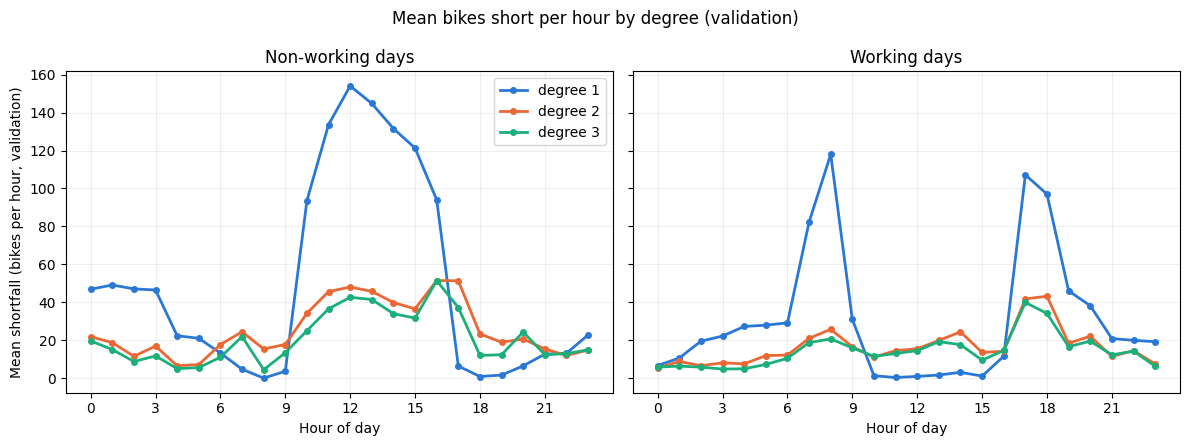

Saved for Phase 3: experiments\phase2\phase2_artifact.json


In [17]:
# A degree's model is the last step of that degree (all of its groups added).
degree_rows = {degree: sequence[sequence["degree"] == degree].iloc[-1] for degree in (1, 2, 3)}
chosen_degree = max(degree_rows, key=lambda degree: degree_rows[degree]["val_r2"])
chosen_row = degree_rows[chosen_degree]
phase2_features, phase2_result = fitted_steps[chosen_row["added group"]]
display(pd.DataFrame(degree_rows).T[["added group", "n_features", "train_r2", "val_r2",
                                     "train_val_r2_gap", "val_rmse", "top_decile_shortfall",
                                     "top_predicted_decile_shortfall", "status", "iterations"]])
print(f"Chosen degree (highest validation R2): {chosen_degree}")

# Operator checks for the three degree models.
degree_predictions = {}
for degree, row in degree_rows.items():
    step_features, step_result = fitted_steps[row["added group"]]
    degree_predictions[f"degree {degree}"] = step_features.transform(val_df) @ step_result.weights

def by_decile(bin_on, column):
    """One column per degree model; a decile no hour falls into stays empty."""
    columns = {}
    for label, pred in degree_predictions.items():
        table = errors_by_demand_decile(y_val, pred, decile_edges, bin_on=bin_on)
        columns[label] = pd.Series(table[column].to_numpy(), index=table["decile"].astype(int))
    return pd.DataFrame(columns).rename_axis("decile")

print("Mean shortfall (bikes) by ACTUAL demand decile:")
display(by_decile("actual", "mean_shortfall_bikes").round(1))
print("Under-prediction rate by ACTUAL demand decile:")
display(by_decile("actual", "under_prediction_rate").round(2))
print("Mean error (predicted - actual) by PREDICTED demand decile (no selection effect):")
display(by_decile("predicted", "mean_error").round(1))
print("Mean shortfall (bikes) by PREDICTED demand decile:")
display(by_decile("predicted", "mean_shortfall_bikes").round(1))

hour_errors = {label: errors_by_hour_daytype(val_df, y_val, pred)
               for label, pred in degree_predictions.items()}
print(f"Hour x day-type cells with the largest shortfall, degree {chosen_degree}:")
display(hour_errors[f"degree {chosen_degree}"]
        .sort_values("mean_shortfall_bikes", ascending=False).head(10).round(1))
plot_shortfall_by_hour(hour_errors, "Mean bikes short per hour by degree (validation)")
plt.show()

save_phase2_artifact(
    config.PHASE2_ARTIFACT, phase2_features, phase2_result, chosen_degree,
    chosen_row.to_dict(), sequence,
    settings={"seed": seed, "step_multiplier": STEP_MULTIPLIER,
              "max_iter": settings1["max_iter"], "tol": settings1["tol"]},
)
print("Saved for Phase 3:", config.PHASE2_ARTIFACT.relative_to(config.ROOT))

In [18]:
# Validation R2 is slightly ABOVE training R2 at degree 2 and 3. Is that a concern?
# Compare errors directly (RMSE), and see how much R2 moves between random
# validation-sized subsets of training rows under the same fitted model.
chosen_X_train = phase2_features.transform(train_df)
chosen_train_pred = chosen_X_train @ phase2_result.weights
chosen_val_pred = phase2_features.transform(val_df) @ phase2_result.weights
train_rmse = regression_metrics(y_train, chosen_train_pred)["rmse"]
val_rmse = regression_metrics(y_val, chosen_val_pred)["rmse"]
print(f"degree {chosen_degree}: RMSE train {train_rmse:.2f}, validation {val_rmse:.2f}; "
      f"target variance validation/train = {y_val.var() / y_train.var():.3f}")

rng = np.random.default_rng(seed)
train_residual = y_train - chosen_train_pred
subset_r2 = []
for _ in range(1000):
    rows = rng.choice(len(y_train), size=len(y_val), replace=False)
    subset_r2.append(1 - np.sum(train_residual[rows] ** 2)
                     / np.sum((y_train[rows] - y_train[rows].mean()) ** 2))
low, high = np.percentile(subset_r2, [5, 95])
print(f"R2 of 1,000 random {len(y_val)}-row subsets of training rows: "
      f"5th-95th percentile {low:.4f} to {high:.4f}")

degree 3: RMSE train 51.74, validation 51.14; target variance validation/train = 1.036
R2 of 1,000 random 2178-row subsets of training rows: 5th-95th percentile 0.9088 to 0.9260


### Degree choice and justification

**Chosen: degree 3** (242 features: Phase 1's 47, five pair groups, two triple groups).

| | Degree 1 | Degree 2 | Degree 3 |
|---|---:|---:|---:|
| validation R² | 0.6823 | 0.9009 | **0.9225** |
| validation RMSE | 103.56 | 57.85 | **51.14** |
| top-decile shortfall, by actual demand (bikes) | 176.6 | 73.6 | **58.9** |
| top-decile shortfall, by predicted demand (bikes) | 134.9 | 53.8 | **43.3** |
| mean error in the top predicted decile (bikes) | −95.9 | −23.8 | **−11.8** |

- Degree 3 has the highest validation R², the rule set before the run. It is also the best model for the operator on every peak measure, so the two criteria agree.
- Every group added helped on validation. The smallest step is temp × hum: +0.0005 R² and −0.1 bikes of top-decile shortfall for one column, effectively nothing. We keep it because Phase 4's L1 penalty is the principled place to drop it.
- No sign of overfitting at this complexity. Training and validation RMSE are almost equal (cell above). Validation R² is slightly higher only because the validation target varies a little more, and the gap is well inside how much R² moves between random validation-sized subsets.
- Every fit converged under the same rule as Phase 1. Degree 3 needed 3,884 updates, and its predictions are within 0.06 bikes of the exact least-squares solution.

Phase 3 tests this formally: it varies complexity around degree 3 and re-evaluates on a chronological split.

### Outcome

_DRAFT — team to review._

1. **Accuracy: right** (degree 2 marginally above our range). Validation R² 0.9009 at degree 2 and 0.9225 at degree 3, against our 0.85–0.90 and 0.90–0.93.
2. **Largest single gain: right**, at the top of our range. hour × workingday alone: +0.149 (0.682 → 0.831). The next largest was hour × yr, +0.037.
3. **Overfitting: better than expected.** The train/validation R² gap turned *negative* (−0.0047 at degree 3). That is not a real advantage:
   - training and validation RMSE are almost equal (51.74 vs 51.14);
   - the validation target varies 3.6% more, which raises its R²;
   - R² on random validation-sized subsets of training rows ranges 0.909–0.926.

   The gap is sampling noise.
4. **Peak shortfall: right.** In the hours the model predicts busiest, the shortfall fell from 134.9 to 43.3 bikes (−68%), and the mean error there from −95.9 to −11.8.
5. **Convergence: right.** Every step converged. Degree 3 needed 3,884 updates, and its predictions are within 0.06 bikes of the exact least-squares solution.

**What surprised us.**
- temp × hum added almost nothing (+0.0005 R², −0.1 bikes of peak shortfall).
- The remaining misses are now scatter rather than bias. The worst cells (weekend 16:00 with 51.4 bikes short, weekend midday, working-day 17:00) have mean errors of only −5 to −20 bikes.
- 120 validation hours are still predicted below zero.

**Handed to Phase 3:** degree 3, the 242 features with lineage, the fitted encoder, scaler and centering means, the weights, the learning rate, and the score of every step (`experiments/phase2/phase2_artifact.json`).

### Bonus follow-up: the asymmetric loss on Phase 2's features

The main bonus (Phase 1 section) stays on Phase 1's features, as the brief asks. This short follow-up reruns the same $k = 3$ model on the features Phase 2 chose, to separate the part of the Phase 1 shift caused by underfitting from the buffer that genuine demand variability justifies.
- *Same code and checks:* `AsymmetricLinearRegressionGD`, a finite-difference gradient check at the Phase 2 weights, and $k = 1$ must reach the Phase 2 weights (up to floating-point rounding) from Phase 2's own start and settings.
- *Same learning-rate rule as the main bonus:* the model's MSE learning rate divided by $k$, warm start from its MSE weights, same stopping rule.
- *Read-only:* the Phase 1 and Phase 2 artifacts must be unchanged afterwards.

### Expectation (bonus follow-up)

_Written before the official run._

With hour × workingday captured, the asymmetric model should no longer lift hours that Phase 1 already over-predicted, such as weekend 08:00. We expect a smaller average upward shift than the 42.6 bikes/h on Phase 1 features, concentrated on hours whose demand varies genuinely (working-day commute peaks, weekend afternoons), and a lower top-decile shortfall than before.

In [19]:
from src.bonus_asymmetric import buffer_by_hour
from src.operator_checks import top_predicted_decile_shortfall
from src.phase2_polynomial import Phase2Features, load_phase2_artifact

phase1_hash = hashlib.sha256(config.PHASE1_ARTIFACT.read_bytes()).hexdigest()
phase2_hash = hashlib.sha256(config.PHASE2_ARTIFACT.read_bytes()).hexdigest()
phase2_artifact = load_phase2_artifact(config.PHASE2_ARTIFACT)
followup_features = Phase2Features.from_dict(phase2_artifact["features"])
Xf_train, Xf_val = followup_features.transform(train_df), followup_features.transform(val_df)
w_phase2 = phase2_artifact["weights"]
settings2 = phase2_artifact["settings"]
print(f"Phase 2 features: degree {phase2_artifact['degree']}, {Xf_train.shape[1] - 1} columns")

# Check 1: analytic gradient against central finite differences at the Phase 2 weights.
analytic = checker.loss_and_gradient(Xf_train, y_train, w_phase2)[1]
numeric = finite_difference_gradient(checker, Xf_train, y_train, w_phase2)
print(f"Check 1: largest relative gradient error = "
      f"{np.max(np.abs(analytic - numeric)) / np.max(np.abs(analytic)):.1e}")

# Check 2: k = 1 from Phase 2's own start and settings reaches the Phase 2
# weights (up to floating-point rounding, as in the main bonus).
k_one_phase2 = AsymmetricLinearRegressionGD(
    under_cost=1.0, learning_rate=phase2_artifact["learning_rate"],
    max_iter=settings2["max_iter"], tol=settings2["tol"],
).fit(Xf_train, y_train, init_weights=followup_features.warm_start(phase1_artifact["weights"]))
weight_gap = np.max(np.abs(k_one_phase2.weights - w_phase2))
print(f"Check 2: k = 1 reaches the Phase 2 weights: largest difference {weight_gap:.1e}; "
      f"{k_one_phase2.iterations} updates vs Phase 2's {phase2_artifact['iterations']}")
assert weight_gap < 1e-8

# The k = 3 fit: Phase 2's learning rate divided by k, warm start from the Phase 2 weights.
followup_result = AsymmetricLinearRegressionGD(
    under_cost=UNDER_COST, learning_rate=phase2_artifact["learning_rate"] / UNDER_COST,
    max_iter=settings2["max_iter"], tol=settings2["tol"],
).fit(Xf_train, y_train, init_weights=w_phase2)
print(f"k = 3 fit: {followup_result.status} after {followup_result.iterations} updates, "
      f"final max|gradient| {followup_result.grad_history[-1]:.2e}, loss ever increased: "
      f"{bool(np.any(np.diff(followup_result.loss_history) > 0))}")
assert followup_result.converged

Phase 2 features: degree 3, 242 columns


Check 1: largest relative gradient error = 1.2e-09


Check 2: k = 1 reaches the Phase 2 weights: largest difference 4.5e-12; 3884 updates vs Phase 2's 3884


k = 3 fit: converged after 7653 updates, final max|gradient| 1.00e-04, loss ever increased: False


In [20]:
# Phase 1 features vs Phase 2 features: where the k = 3 buffer goes (validation).
pred_mse2 = Xf_val @ w_phase2
pred_asym2 = Xf_val @ followup_result.weights

buffers = buffer_by_hour(val_df, y_val, pred_mse, pred_asym).merge(
    buffer_by_hour(val_df, y_val, pred_mse2, pred_asym2),
    on=["workingday", "hr"], suffixes=("_phase1_features", "_phase2_features"))
buffers = buffers[["workingday", "hr",
                   "shift_phase1_features", "shift_phase2_features",
                   "short_phase1_features", "short_phase2_features",
                   "idle_phase1_features", "idle_phase2_features"]]
print("Mean upward shift and the asymmetric model's bikes short / idle per hour (validation):")
display(buffers.round(1))
buffers.to_csv(config.BONUS_DIR / "followup_buffer_by_hour.csv", index=False)

followup_models = {
    "Phase 1 features, MSE": pred_mse,
    "Phase 1 features, k=3": pred_asym,
    "Phase 2 features, MSE": pred_mse2,
    "Phase 2 features, k=3": pred_asym2,
}
display(pd.DataFrame({
    label: {
        **prediction_summary(y_val, pred, UNDER_COST),
        "top_decile_shortfall": top_decile_shortfall(y_val, pred, decile_edges),
        "top_predicted_decile_shortfall":
            top_predicted_decile_shortfall(y_val, pred, decile_edges),
    }
    for label, pred in followup_models.items()
}).round(3))

# Check 3: both artifacts are unchanged by the follow-up.
assert hashlib.sha256(config.PHASE1_ARTIFACT.read_bytes()).hexdigest() == phase1_hash
assert hashlib.sha256(config.PHASE2_ARTIFACT.read_bytes()).hexdigest() == phase2_hash
print("Check 3: Phase 1 and Phase 2 artifacts unchanged by the follow-up")

Mean upward shift and the asymmetric model's bikes short / idle per hour (validation):


,workingday,hr,shift_phase1_features,shift_phase2_features,short_phase1_features,short_phase2_features,idle_phase1_features,idle_phase2_features
0,0,0,41.1,11.4,19.6,12.4,15.1,11.2
1,0,1,42.9,12.5,27.4,9.3,28.1,12.3
2,0,2,39.7,11.7,21.9,5.7,24.5,22.0
3,0,3,39.7,10.7,26.8,6.5,36.2,11.9
4,0,4,41.9,6.5,11.3,2.5,58.3,12.6
5,0,5,40.6,6.7,11.6,3.0,60.9,16.0
6,0,6,39.9,12.6,6.7,6.9,106.9,20.3
7,0,7,69.0,15.5,2.2,17.1,239.9,28.8
8,0,8,98.3,28.9,0.0,0.4,375.8,50.0
9,0,9,35.9,17.8,0.7,6.6,80.7,25.2


,"Phase 1 features, MSE","Phase 1 features, k=3","Phase 2 features, MSE","Phase 2 features, k=3"
r2,0.682,0.606,0.923,0.907
rmse,103.558,115.349,51.144,56.040
asymmetric_cost,11144.979,9343.450,2569.052,2158.774
mean_prediction,196.380,238.958,194.459,213.350
under_prediction_rate,0.458,0.322,0.491,0.319
mean_shortfall_bikes,37.175,21.171,16.621,8.917
mean_surplus_bikes,39.550,66.125,17.076,28.263
top_decile_shortfall,176.642,112.126,58.863,34.072
top_predicted_decile_shortfall,134.858,59.606,43.269,23.285


Check 3: Phase 1 and Phase 2 artifacts unchanged by the follow-up


### Outcome (bonus follow-up)

_DRAFT — team to review._

**Checks.** All three passed:
- the gradient matched finite differences (relative error 1.2·10⁻⁹);
- k = 1 reached the Phase 2 weights (largest difference 4.5·10⁻¹², same 3,884 updates);
- both artifacts were unchanged.

The k = 3 fit converged after 7,653 updates.

- **Smaller average shift: right.** +18.9 bikes/hour (mean prediction 194.5 → 213.4), against +42.6 on Phase 1's features.
- **Aimed at genuinely variable hours: mostly right.** The largest shifts are at weekend 17:00 (+41.1), 13:00 (+39.5), 12:00 (+36.8) and working-day 18:00 (+38.3), 17:00 (+37.0). Night hours now get only +6 to +13.
- **No more lift at weekend 08:00: partly wrong.** It is still raised by +28.9 (was +98.3). There the asymmetric model leaves 0.4 bikes short but 50.0 idle per hour.
- **Lower top-decile shortfall: right.** 58.9 → 34.1 bikes by actual demand, and 43.3 → 23.3 by predicted demand. On Phase 1's features it was 112.1 and 59.6.
- **Price of the hedge:** R² 0.923 → 0.907. That is −0.016, against −0.076 on Phase 1's features. Bikes short per hour 16.6 → 8.9; idle 17.1 → 28.3.

**Lesson.** Once the underfitting is removed, the asymmetric buffer is cheap, and it goes mostly where demand is genuinely variable.

## Phase 3 — Bias–Variance Tradeoff

### Phase 3 plan: what we vary, what we measure, how we decide

**Consumes** Phase 2's artifact: its groups, in its order, and its chosen design.

**1. Complexity sweep** (seeded split). Phase 1 → each Phase 2 group in Phase 2's order → then *beyond* Phase 2, to reach the high-variance side:
- hour × holiday, hour × weekday, hour × month and full hour × weathersit (the groups rejected in Phase 2 Step A);
- a degree-4 group: hour × workingday × yr × season, with the lower-order terms it needs.

Some extension columns are exact combinations of earlier columns: hour × month contains hour × season, full hour × weathersit contains the hour blocks, and hour × weekday plus hour × holiday reproduce hour × workingday. Those columns are detected on the training rows (QR factorization, columns in order) and dropped. The count is reported.

Each fit uses the same GD, learning-rate rule (1.9/λ_max), stopping rule and cap as Phases 1 and 2:
- Phase 2's steps start from the Phase 1 weights exactly as in Phase 2, so they must reproduce Phase 2's recorded scores (asserted).
- The extensions start from Phase 2's chosen fit plus zeros.
- A fit that hits the cap is **flagged as not converged and never called over-fitted**. Its exact least-squares score is shown for reference only.

**2. What tells bias from variance.**
- *Sweep:* on the bias side, train and validation improve together and the gap stays near 0. On the variance side, train keeps improving while validation stalls or falls, and the gap opens.
- *Learning curves* (train/validation RMSE vs training rows; 25%, 50%, 75%, 100% of the training portion; validation fixed), for Phase 2's design and the largest extended design. Curves that converge with a small, flat gap mean bias-limited: more data would not help. A wide gap that closes as data grows means variance-limited.

**3. The chronological split** (the only other split). Hold out the last 20% of labeled *days*, so whole days stay on one side; the cut uses dates only. Everything is refitted on the earlier days: encoder levels, scaler, centering means, the Phase 1 GD, and every sweep step.
- The seeded validation hours share days, weather and periods with training hours: it measures interpolation.
- The chronological holdout lies after all training data, in a later and busier stretch of 2012: it measures extrapolation in time.
- The hidden test (day 20 of every month, both years) is neither: its days are unseen but sit inside the training period.

**4. Operator checks** for every fit: top-decile shortfall by actual and by predicted demand.

**5. Decision rules, fixed before the run.**
- *Target for Phase 4:* among converged fits on the seeded split, the one with the fewest features whose validation R² is within `R2_TOLERANCE` of the best.
- *Noise candidates:* groups in the target design whose addition raised validation R² by less than `R2_TOLERANCE` on **both** splits **and** lowered the seeded top-decile shortfall by less than `SHORTFALL_TOLERANCE` bikes.

In [21]:
from src.data import chronological_split
from src.phase2_polynomial import load_phase2_artifact
from src.visualization import plot_complexity_sweep, plot_learning_curves, plot_split_comparison
from src.phase3_bias_variance import (
    SWEEP_EXTENSIONS,
    choose_target,
    fit_phase1,
    group_support,
    learning_curve,
    run_sweep,
    save_phase3_artifact,
    step_contributions,
    sweep_steps,
)

# Phase 3 consumes Phase 2's artifact: its groups, order and chosen design.
phase2_artifact = load_phase2_artifact(config.PHASE2_ARTIFACT)
steps = sweep_steps(phase2_artifact)
display(pd.DataFrame([{"step": i, "added group": s["added group"], "degree": s["degree"],
                       "part": s["part"], "groups so far": len(s["groups"]),
                       "starts from": s.get("start_from", "Phase 1 weights")}
                      for i, s in enumerate(steps)]))

# Extension designs on the seeded training rows only (nothing fitted here).
extension_rows = []
for step in steps:
    if step["part"] != "extension":
        continue
    design = Phase2Features(phase1_features, step["groups"]).fit(train_df)
    X_tr = design.transform(train_df)
    eigenvalues = np.linalg.eigvalsh(X_tr.T @ X_tr / len(X_tr))
    extension_rows.append({"added group": step["added group"], "degree": step["degree"],
                           "n_features": X_tr.shape[1] - 1,
                           "dropped_so_far": len(design.dropped),
                           "condition_number": eigenvalues[-1] / eigenvalues[0],
                           **group_support(design, train_df, step["added group"])})
display(pd.DataFrame(extension_rows))

# The chronological split: dates only.
chrono_train, chrono_val, first_validation_day = chronological_split(train_all)
print(f"chronological split: {chrono_train['dteday'].nunique()} earlier days "
      f"({len(chrono_train)} rows) | {chrono_val['dteday'].nunique()} later days "
      f"({len(chrono_val)} rows), from {first_validation_day} to {chrono_val['dteday'].max()}")

,step,added group,degree,part,groups so far,starts from
0,0,(Phase 1),1,Phase 2,0,Phase 1 weights
1,1,hour x workingday,2,Phase 2,1,Phase 1 weights
2,2,hour x yr,2,Phase 2,2,Phase 1 weights
3,3,hour x season,2,Phase 2,3,Phase 1 weights
4,4,hour-block x weathersit,2,Phase 2,4,Phase 1 weights
5,5,temp x hum,2,Phase 2,5,Phase 1 weights
6,6,hour x workingday x yr,3,Phase 2,6,Phase 1 weights
7,7,hour x workingday x temp,3,Phase 2,7,Phase 1 weights
8,8,hour x holiday,2,extension,8,hour x workingday x temp
9,9,hour x weekday,2,extension,9,hour x workingday x temp


,added group,degree,n_features,dropped_so_far,condition_number,terms_kept,min_support_rows,terms_under_30_rows
0,hour x holiday,2,265,0,1713.431231,23,7,23
1,hour x weekday,2,380,23,1726.853910,115,41,0
2,hour x month,2,564,92,5062.351583,184,23,62
3,hour x weathersit,2,602,100,5198.395622,38,21,11
4,hour x workingday x yr x season,4,818,100,5530.027475,216,26,15


chronological split: 365 earlier days (8703 rows) | 91 later days (2183 rows), from 2012-08-05 to 2012-12-19


### Expectation

_Written before the official run._

1. **Where seeded validation peaks.** We expect a plateau, not a sharp peak: the extensions should move seeded validation R² by only a few thousandths around Phase 2's 0.9225. On a random split, hours from the same day fall in both training and validation, so even sparse terms (hour × holiday, hour × month) partly "recognise" validation days, which hides overfitting. If any extension visibly hurts, we expect it to be hour × holiday first (23 terms on 7–30 rows each) or degree 4 (216 extra columns).

2. **Train/validation gap.** Training R² keeps rising with every extension, because a larger linear model can never fit its own training data worse, while validation stays flat. The gap therefore widens from about −0.005 to roughly +0.01–0.02 at 818 features.

3. **Convergence.** The condition numbers rise about 3× (1,713 → 5,530). GD updates grow roughly in proportion, from 3,884 to around 10,000–15,000, so we expect every fit to converge within the 50,000 cap.

4. **Learning curves.** The Phase 2 design should be bias/noise-limited: training and validation RMSE close together and flattening near 51, so more data would barely help. The 818-feature design should be variance-limited: at 25% of the data (~2,200 rows for 818 weights) a wide gap, shrinking as data is added.

5. **Chronological vs seeded.** The chronological holdout (Aug–Dec 2012) is the busiest period and lies after everything the model trained on. We expect validation R² around 0.89–0.91 for the degree-3 design, with RMSE around 65–75 bikes against 51 on the seeded split; exploration on an almost identical boundary gave 0.89 / 71 bikes for a similar ~200-feature design. The extensions should hurt more here than on the seeded split, especially degree 4: the earlier part contains no 2012 autumn hours, so the year × season terms must extrapolate to a combination never seen in training.
   Which estimate to trust: the chronological score for forecasting genuinely future periods; the seeded score is optimistic because it shares days with training. The hidden test (day 20 of every month, both years) lies between the two: unseen days, but inside the period the final model is fitted on. We therefore expect test performance slightly below the seeded estimate and above the chronological one.

6. **Operator checks.** Larger peak shortfalls on the chronological split than on the seeded one, since a model fitted before the late-2012 growth under-predicts its busiest hours.

7. **Diagnosis and target.** At degree 3 the model is bias/noise-limited, not variance-limited, so the target stays the Phase 2 degree-3 design (243 features). Noise candidates: temp × hum (+0.0005 R² in Phase 2) among current terms; the extensions (hour × holiday, hour × month, degree 4) are where variance enters.

**Decision rules, fixed before the run:** the target is the converged fit with the fewest features whose seeded validation R² is within 0.002 of the best. A group is a noise candidate only if it gains < 0.002 R² on both splits AND reduces the peak shortfall by < 1 bike.

Phase 2 steps reproduce Phase 2's recorded validation R2
Scores and operator checks (validation unless marked train):


,added group,part,degree,n_features,train_r2,val_r2,train_val_r2_gap,train_rmse,val_rmse,top_decile_shortfall,top_predicted_decile_shortfall
0,(Phase 1),Phase 2,1,47,0.6970,0.6823,0.0147,99.3378,103.5582,176.6417,134.8579
1,hour x workingday,Phase 2,2,70,0.8316,0.8310,0.0007,74.0519,75.5381,110.7418,87.9871
2,hour x yr,Phase 2,2,93,0.8641,0.8675,-0.0034,66.5373,66.8875,91.7901,77.3933
3,hour x season,Phase 2,2,162,0.8933,0.8937,-0.0004,58.9591,59.9108,76.3474,56.4976
4,hour-block x weathersit,Phase 2,2,170,0.8979,0.9004,-0.0025,57.6654,57.9894,73.6795,54.1321
5,temp x hum,Phase 2,2,171,0.8993,0.9009,-0.0016,57.2749,57.8544,73.5595,53.7660
6,hour x workingday x yr,Phase 2,3,195,0.9078,0.9105,-0.0026,54.7996,54.9828,65.9146,50.4114
7,hour x workingday x temp,Phase 2,3,242,0.9178,0.9225,-0.0047,51.7387,51.1439,58.8631,43.2694
8,hour x holiday,extension,2,265,0.9204,0.9223,-0.0018,50.9102,51.2259,58.3497,45.6809
9,hour x weekday,extension,2,380,0.9264,0.9249,0.0014,48.9690,50.3425,55.2842,43.6966


Convergence (exact_val_r2 = exact least-squares fit, reference only):


,added group,n_features,dropped_columns,condition_number,status,iterations,final_max_abs_gradient,gap_to_exact_bikes,val_r2,exact_val_r2
0,(Phase 1),47,0,55.825784,converged,0,0.0001,0.007415,0.682332,0.682331
1,hour x workingday,70,0,191.184385,converged,757,0.0001,0.019002,0.830980,0.830981
2,hour x yr,93,0,199.252619,converged,789,0.0001,0.019036,0.867476,0.867476
3,hour x season,162,0,467.892893,converged,1748,0.0001,0.041577,0.893680,0.893680
4,hour-block x weathersit,170,0,471.953860,converged,1756,0.0001,0.041681,0.900390,0.900390
5,temp x hum,171,0,477.784380,converged,1758,0.0001,0.041759,0.900853,0.900853
6,hour x workingday x yr,195,0,478.083906,converged,1759,0.0001,0.041660,0.910451,0.910451
7,hour x workingday x temp,242,0,1712.747762,converged,3884,0.0001,0.058652,0.922519,0.922519
8,hour x holiday,265,0,1713.431231,converged,992,0.0001,0.067185,0.922271,0.922271
9,hour x weekday,380,23,1726.853910,converged,2412,0.0001,0.082071,0.924929,0.924929


validation peak (converged fits): hour x workingday x yr x season, 818 features, R2 0.9274


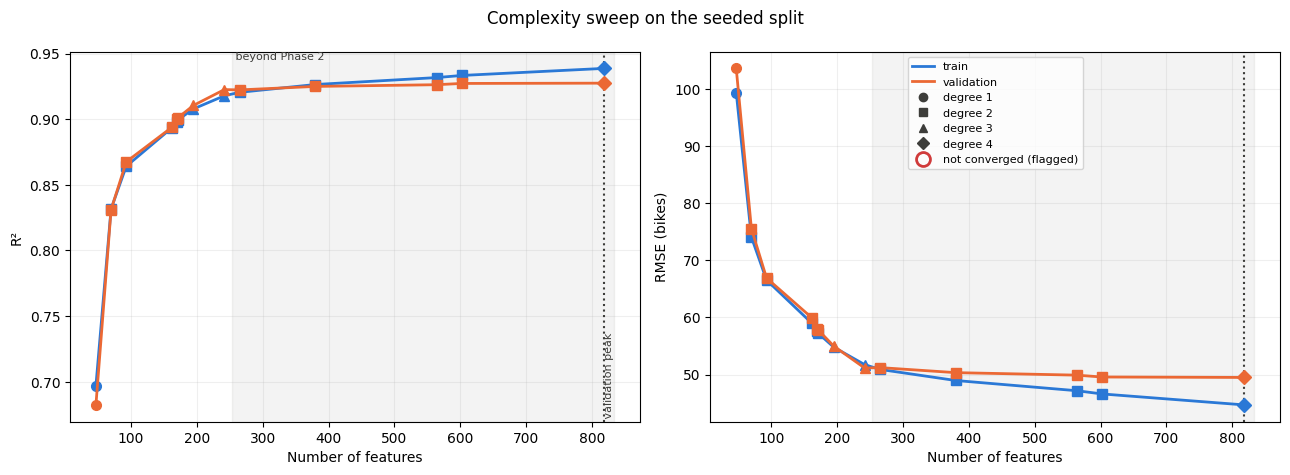

In [22]:
# The sweep on the seeded split, with the same rules as Phase 2.
settings2 = phase2_artifact["settings"]
STEP3, MAX_ITER3, TOL3 = settings2["step_multiplier"], settings2["max_iter"], settings2["tol"]
seeded_sweep, seeded_fits = run_sweep(steps, train_df, y_train, val_df, y_val,
                                      phase1_features, phase1_artifact["weights"],
                                      STEP3, MAX_ITER3, TOL3)

# Integrity: Phase 2's steps must reproduce the scores Phase 2 recorded.
recorded = pd.DataFrame(phase2_artifact["sequence"]).set_index("added group")["val_r2"]
reproduced = seeded_sweep.set_index("added group").loc[recorded.index, "val_r2"]
assert np.allclose(recorded, reproduced, rtol=0, atol=1e-10)
print("Phase 2 steps reproduce Phase 2's recorded validation R2")

config.PHASE3_DIR.mkdir(parents=True, exist_ok=True)
seeded_sweep.to_csv(config.PHASE3_DIR / "sweep_seeded.csv", index=False)
print("Scores and operator checks (validation unless marked train):")
display(seeded_sweep[["added group", "part", "degree", "n_features", "train_r2", "val_r2",
                      "train_val_r2_gap", "train_rmse", "val_rmse", "top_decile_shortfall",
                      "top_predicted_decile_shortfall"]].round(4))
print("Convergence (exact_val_r2 = exact least-squares fit, reference only):")
display(seeded_sweep[["added group", "n_features", "dropped_columns", "condition_number",
                      "status", "iterations", "final_max_abs_gradient", "gap_to_exact_bikes",
                      "val_r2", "exact_val_r2"]])

converged = seeded_sweep[seeded_sweep["status"] == "converged"]
peak = converged.loc[converged["val_r2"].idxmax()]
print(f"validation peak (converged fits): {peak['added group']}, "
      f"{peak['n_features']} features, R2 {peak['val_r2']:.4f}")
first_extension = seeded_sweep[seeded_sweep["part"] == "extension"]["n_features"].min()
last_phase2 = seeded_sweep[seeded_sweep["part"] == "Phase 2"]["n_features"].max()
plot_complexity_sweep(seeded_sweep, "Complexity sweep on the seeded split",
                      peak["n_features"], (first_extension + last_phase2) / 2)
plt.show()

Phase 2's chosen design


,fraction,n_train,n_features,dropped_columns,status,iterations,final_max_abs_gradient,train_rmse,val_rmse,val_r2,exact_val_rmse
0,0.25,2177,242,0,converged,4390,0.0,46.237,54.243,0.913,54.243
1,0.50,4354,242,0,converged,4771,0.0,49.796,52.116,0.920,52.116
2,0.75,6531,242,0,converged,5048,0.0,51.888,51.717,0.921,51.717
3,1.00,8708,242,0,converged,4672,0.0,51.739,51.144,0.923,51.144


largest extended design


,fraction,n_train,n_features,dropped_columns,status,iterations,final_max_abs_gradient,train_rmse,val_rmse,val_r2,exact_val_rmse
0,0.25,2177,811,107,converged,15631,0.0,34.868,60.917,0.890,60.917
1,0.50,4354,818,100,converged,10009,0.0,41.398,52.995,0.917,52.995
2,0.75,6531,818,100,converged,7744,0.0,44.351,50.984,0.923,50.984
3,1.00,8708,818,100,converged,4048,0.0,44.700,49.503,0.927,49.503


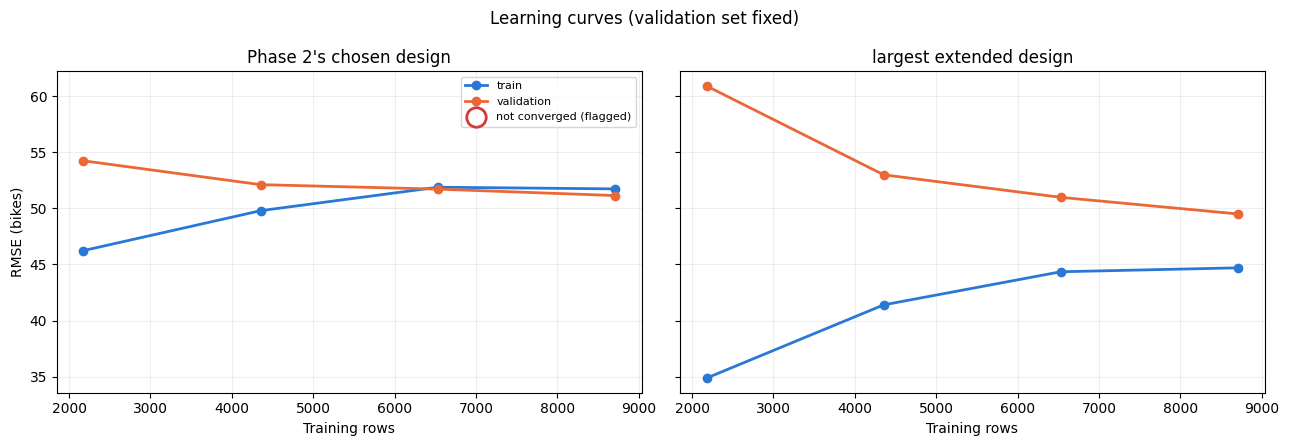

In [23]:
# Learning curves: refit everything on growing subsets of the training portion.
FRACTIONS = [0.25, 0.5, 0.75, 1.0]
phase1_state = phase1_artifact["features"]
curve_designs = {
    "Phase 2's chosen design": list(phase2_artifact["groups"]),
    "largest extended design": steps[-1]["groups"],
}
curves = {}
for label, groups in curve_designs.items():
    curves[label] = learning_curve(groups, phase1_state["seasonal"], phase1_state["use_trend"],
                                   train_df, y_train, val_df, y_val, FRACTIONS, seed,
                                   STEP3, MAX_ITER3, TOL3)
    print(label)
    display(curves[label].round(3))
pd.concat(curves, names=["design"]).to_csv(config.PHASE3_DIR / "learning_curves.csv")
plot_learning_curves(curves, "Learning curves (validation set fixed)")
plt.show()

earlier days, rows per year (0 = 2011) x season (1 = winter ... 4 = autumn):


season,1,2,3,4
yr,,,,
0,1323,1367,1365,1367
1,1363,1366,552,0


,added group,n_features (seeded),n_features (chrono),seeded_val_r2,chrono_train_r2,chrono_val_r2,seeded_val_rmse,chrono_val_rmse,chrono_status,seeded_top_decile_shortfall,chrono_top_decile_shortfall,chrono_top_predicted_decile_shortfall,chrono_top_predicted_decile_mean_error
0,(Phase 1),47,47,0.6823,0.6946,0.6376,103.5582,130.9556,converged,176.6417,197.3495,168.2936,-128.7395
1,hour x workingday,70,70,0.8310,0.8271,0.7986,75.5381,97.6363,converged,110.7418,143.4654,157.4209,-150.4492
2,hour x yr,93,93,0.8675,0.8535,0.8613,66.8875,81.0181,converged,91.7901,109.3245,102.2184,-84.9781
3,hour x season,162,162,0.8937,0.8892,0.8808,59.9108,75.0995,converged,76.3474,87.8512,76.6140,-50.1195
4,hour-block x weathersit,170,170,0.9004,0.8949,0.8852,57.9894,73.6977,converged,73.6795,86.1994,74.4711,-49.0407
5,temp x hum,171,171,0.9009,0.8960,0.8867,57.8544,73.2297,converged,73.5595,86.3114,75.4984,-50.5521
6,hour x workingday x yr,195,195,0.9105,0.9022,0.9047,54.9828,67.1669,converged,65.9146,74.3981,63.6810,-38.0702
7,hour x workingday x temp,242,242,0.9225,0.9154,0.9094,51.1439,65.4903,converged,58.8631,74.7483,66.7185,-47.7905
8,hour x holiday,265,265,0.9223,0.9176,0.9114,51.2259,64.7413,converged,58.3497,73.8010,65.4285,-46.1105
9,hour x weekday,380,380,0.9249,0.9231,0.9167,50.3425,62.7861,converged,55.2842,71.8682,64.9246,-46.6659


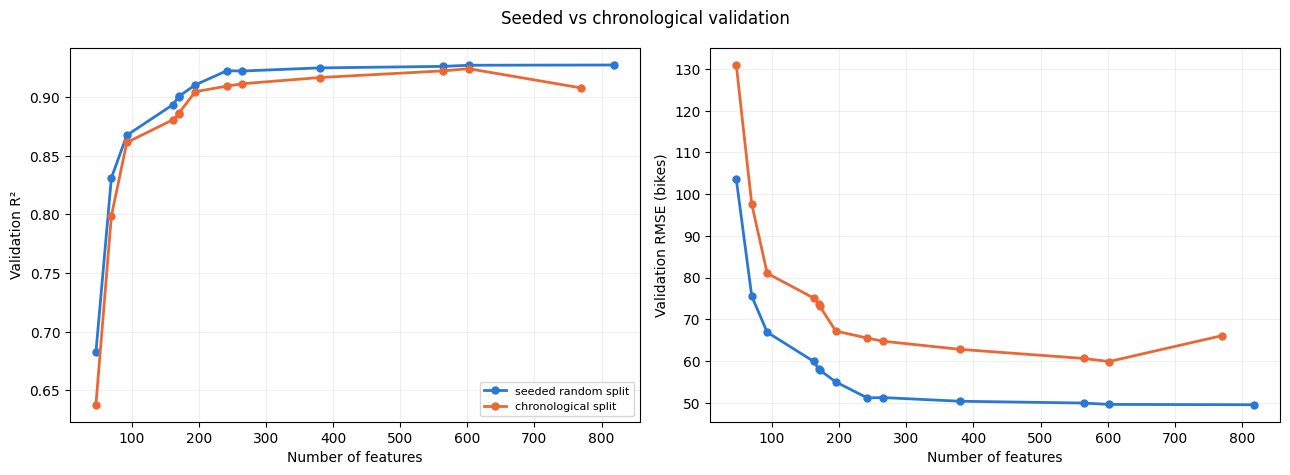

In [24]:
# The same sweep on the chronological split, everything refitted on the earlier days.
yc_train = chrono_train[config.TARGET].to_numpy(dtype=float)
yc_val = chrono_val[config.TARGET].to_numpy(dtype=float)
chrono_phase1, chrono_phase1_result = fit_phase1(
    chrono_train, yc_train, phase1_state["seasonal"], phase1_state["use_trend"],
    STEP3, MAX_ITER3, TOL3)
assert chrono_phase1_result.converged
chrono_sweep, chrono_fits = run_sweep(steps, chrono_train, yc_train, chrono_val, yc_val,
                                      chrono_phase1, chrono_phase1_result.weights,
                                      STEP3, MAX_ITER3, TOL3)
chrono_sweep.to_csv(config.PHASE3_DIR / "sweep_chronological.csv", index=False)
print("earlier days, rows per year (0 = 2011) x season (1 = winter ... 4 = autumn):")
display(chrono_train.groupby(["yr", "season"]).size().unstack(fill_value=0))

comparison = pd.DataFrame({
    "added group": seeded_sweep["added group"],
    "n_features (seeded)": seeded_sweep["n_features"],
    "n_features (chrono)": chrono_sweep["n_features"],
    "seeded_val_r2": seeded_sweep["val_r2"],
    "chrono_train_r2": chrono_sweep["train_r2"],
    "chrono_val_r2": chrono_sweep["val_r2"],
    "seeded_val_rmse": seeded_sweep["val_rmse"],
    "chrono_val_rmse": chrono_sweep["val_rmse"],
    "chrono_status": chrono_sweep["status"],
    "seeded_top_decile_shortfall": seeded_sweep["top_decile_shortfall"],
    "chrono_top_decile_shortfall": chrono_sweep["top_decile_shortfall"],
    "chrono_top_predicted_decile_shortfall": chrono_sweep["top_predicted_decile_shortfall"],
    "chrono_top_predicted_decile_mean_error": chrono_sweep["top_predicted_decile_mean_error"],
})
display(comparison.round(4))
plot_split_comparison(seeded_sweep, chrono_sweep, "Seeded vs chronological validation")
plt.show()

In [25]:
# Decision rules fixed before the run (see the plan above and the Expectation).
R2_TOLERANCE = 0.002        # validation R2 differences smaller than this count as ties
SHORTFALL_TOLERANCE = 1.0   # bikes of top-decile shortfall

target = choose_target(seeded_sweep, R2_TOLERANCE)
target_features, target_result = seeded_fits[target["added group"]]
print(f"Target for Phase 4: design up to '{target['added group']}' "
      f"({target['n_features']} features, validation R2 {target['val_r2']:.4f})")

contributions = step_contributions(seeded_sweep, chrono_sweep)
display(contributions.round(4))
in_target = contributions["added group"].isin(target_features.groups)
noise = contributions[in_target
                      & (contributions["seeded_val_r2_change"] < R2_TOLERANCE)
                      & (contributions["chrono_val_r2_change"] < R2_TOLERANCE)
                      & (contributions["seeded_top_decile_shortfall_change"] > -SHORTFALL_TOLERANCE)]
noise_candidates = noise["added group"].tolist()
print("Noise candidates for the Phase 4 penalty:", noise_candidates or "none")

largest = seeded_sweep.iloc[-1]
diagnosis = {
    "seeded_validation_peak": {"step": peak["added group"], "n_features": int(peak["n_features"]),
                               "val_r2": float(peak["val_r2"])},
    "target_train_val_r2_gap": float(target["train_val_r2_gap"]),
    "largest_train_val_r2_gap": float(largest["train_val_r2_gap"]),
    "largest_status": largest["status"],
    "learning_curve_final_gap_rmse": {
        label: float(table["val_rmse"].iloc[-1] - table["train_rmse"].iloc[-1])
        for label, table in curves.items()},
    "target_val_r2": {"seeded": float(target["val_r2"]),
                      "chronological": float(chrono_sweep.set_index("added group")
                                             .loc[target["added group"], "val_r2"])},
    "r2_tolerance": R2_TOLERANCE,
    "shortfall_tolerance": SHORTFALL_TOLERANCE,
}
save_phase3_artifact(
    config.PHASE3_ARTIFACT, target, target_features, target_result.weights, diagnosis,
    noise_candidates,
    tables={"seeded_sweep": seeded_sweep, "chronological_sweep": chrono_sweep,
            "contributions": contributions},
    settings={"seed": seed, "first_chronological_validation_day": first_validation_day,
              "step_multiplier": STEP3, "max_iter": MAX_ITER3, "tol": TOL3},
)
print("Saved for Phase 4:", config.PHASE3_ARTIFACT.relative_to(config.ROOT))

Target for Phase 4: design up to 'hour x month' (564 features, validation R2 0.9262)


,added group,part,n_features,seeded_val_r2_change,seeded_top_decile_shortfall_change,seeded_converged,chrono_val_r2_change,chrono_top_decile_shortfall_change,chrono_converged
0,(Phase 1),Phase 2,47,NaN,NaN,True,NaN,NaN,True
1,hour x workingday,Phase 2,70,0.1486,-65.9000,True,0.1609,-53.8842,True
2,hour x yr,Phase 2,93,0.0365,-18.9517,True,0.0627,-34.1409,True
3,hour x season,Phase 2,162,0.0262,-15.4427,True,0.0195,-21.4733,True
4,hour-block x weathersit,Phase 2,170,0.0067,-2.6678,True,0.0044,-1.6518,True
5,temp x hum,Phase 2,171,0.0005,-0.1200,True,0.0015,0.1120,True
6,hour x workingday x yr,Phase 2,195,0.0096,-7.6449,True,0.0180,-11.9133,True
7,hour x workingday x temp,Phase 2,242,0.0121,-7.0515,True,0.0047,0.3502,True
8,hour x holiday,extension,265,-0.0002,-0.5134,True,0.0021,-0.9474,True
9,hour x weekday,extension,380,0.0027,-3.0655,True,0.0053,-1.9327,True


Noise candidates for the Phase 4 penalty: ['temp x hum']
Saved for Phase 4: experiments\phase3\phase3_artifact.json


### Outcome

_DRAFT — team to review._

1. **Seeded plateau: right.** Seeded validation R² moved from 0.9225 to 0.9274 at 818 features. hour × holiday was the only step that lowered it (−0.0002).
2. **Gap: right.** −0.0047 → +0.0112 at 818 features.
3. **Convergence: right.** All 13 fits converged on both splits; the largest took 11,761 updates.
4. **Learning curves: right.**
   - Phase 2's design: training and validation RMSE meet near 51 from 75% of the data. It is bias-limited.
   - 818 features: the gap is 26 bikes at 25% of the data (34.9 vs 60.9) and 4.8 at 100% (44.7 vs 49.5), still closing. It is variance-limited.
5. **Chronological split.**
   - *(a) Level: right.* Degree 3 scores R² 0.9094 and RMSE 65.5, against 0.9225 and 51.1 on the seeded split.
   - *(b) Extensions hurt more: wrong, except degree 4.* hour × holiday, weekday, month and weathersit raised chronological R² by +0.0149 (0.9094 → 0.9243), more than on the seeded split (+0.0047). Degree 4 did hurt: −0.0165 R², +11.2 bikes of peak shortfall.
   - Our mechanism was right for degree 4. The earlier days contain no 2012-autumn hours, so those columns are constant and dropped (770 instead of 818 features), and the 2012-summer terms are fitted on July and early August only.
6. **Chronological shortfalls: right.** Degree 3: 74.7 vs 58.9 bikes by actual demand, 66.7 vs 43.3 by predicted demand. In its top predicted decile the mean error is −47.8 bikes, against −11.8 on the seeded split.
7. **Target: wrong.** Our pre-registered rule picked **564 features**: degree 3 plus hour × holiday, hour × weekday and hour × month. Its validation R² (0.9262) is within 0.002 of the best (0.9274); degree 3 (0.9225) is not. Noise candidate: temp × hum, as expected.

**Diagnosis.**
- *Degree 3 is bias-limited, not variance-limited:* the train/validation gap is about zero and its learning curve is flat.
- *Adding groups up to 602 features removes more bias, on both splits;* these terms are not fitting noise.
- *Variance enters only at degree 4,* where the training R² keeps rising (0.936 on the earlier days) while chronological validation falls to 0.908.
- *Which estimate to trust:* the chronological score for forecasting later periods; the seeded score is optimistic because it shares days with training. Both splits rank the designs the same way up to 602 features, which supports the target.
- *On the hidden test* (day 20 of each month, inside the training period), we expect a score between the two estimates.

**Handed to Phase 4:** the 564-feature target with lineage, its fitted encoder/scaler/centering means and converged weights, the diagnosis numbers, and the noise candidate temp × hum (`experiments/phase3/phase3_artifact.json`).

## Phase 4 — Regularization

### Phase 4 plan: objective, search, selection and verdicts

**Consumes** Phase 3's artifact: the 564-feature target design (encoder, scaler, centering means, feature names, lineage), its diagnosis (bias-limited at degree 3; variance enters only past the target), and the noise candidate (temp × hum). Same seeded split and scaler.

**One objective for all three methods** (intercept $w_0$ never penalized):
$$J(w) = \frac{1}{2n}\lVert Xw - y\rVert^2 + \lambda\Big(\rho\sum_{j\ge1}|w_j| + (1-\rho)\sum_{j\ge1}\tfrac{w_j^2}{2}\Big)$$
Ridge: $\rho = 0$. Lasso: $\rho = 1$. Elastic Net: $\rho \in \{0.1, 0.5, 0.9\}$.

**Algorithm** (`PenalizedGD`, the Phase 1 loop with $H = X^\top X/n$, $b = X^\top y/n$ computed once per fit):
1. Gradient step on the smooth part: $H w - b + \lambda(1-\rho)\,w_{\text{pen}}$. Ridge's penalty simply adds $\lambda(1-\rho)$ to the diagonal of $H$, except the intercept's.
2. Soft-thresholding for the L1 part: each penalized weight is pulled toward 0 by $\eta\lambda\rho$ and set to **exactly** 0 if it would cross 0.
- *Learning rate:* $L = \lambda_{max}(H) + \lambda(1-\rho)$ bounds the curvature of the smooth part.
  - Ridge is plain gradient descent on a quadratic, so it keeps Phases 1–3's rule, $1.9/L$ (stable for any step below $2/L$).
  - Lasso and Elastic Net use $1/L$: soft-thresholding steps of at most $1/L$ are guaranteed never to increase the objective. Every fit reports `objective_ever_increased` as the check.
- *Stopping:* the largest entry of $(w - w_{next})/\eta$ falls below 1e-4, cap 50,000 updates. Without L1 this is exactly the gradient; with L1 it is 0 only at the minimum.
- *Checks:* tests show the code matches Ridge's closed-form solution and satisfies the Lasso optimality conditions.

**λ search: one path per method, from strong to weak.**
- Lasso and Elastic Net start at $\lambda_{max}$, the smallest λ at which every penalized weight is exactly 0, and go down to $10^{-4}\lambda_{max}$.
- Ridge has no exact-zero point, so its path runs from $10^{3}$ (every weight shrunk close to 0) down to $10^{-5}$ (essentially unpenalized).
- 30 log-spaced values per path. Each fit starts from the previous fit's weights, which makes the path cheap.
- **Revision after the first official run.** All four L1-type paths reached their best validation R² at the last grid point. For Lasso and Elastic Net 0.9 the curve had already flattened at the unpenalized level. For Elastic Net 0.5 (0.0007 short) and especially Elastic Net 0.1 (0.012 short, ending at λ = 0.07) the grid stopped before the peak, so the comparison between ratios was cut off. Every L1-type path now continues at the same spacing (4/29 of a decade) down to λ = 1e-5, Ridge's floor. Their first 30 values are unchanged. Ridge's grid is unchanged: it peaked inside.
- *Why this range:* Phase 3 found the target bias-limited, with variance only in its sparse terms. So we expect the best λ to be small, and the grid reaches far enough down to see the unpenalized end.

**Selection on the seeded validation set.** The brief fixes a single validation set for all tuning, so there is no k-fold cross-validation. A single holdout makes the chosen λ itself somewhat noisy, which is why near-ties count as ties. Only converged fits are eligible.
- Ridge: the highest validation R².
- Lasso and each Elastic Net ratio: the **largest** λ whose validation R² is within 0.002 of that path's best. Among equally good fits, this prefers the sparser, more stable one.
- Elastic Net overall: the ratio whose selected fit has the highest validation R² (ties: fewer nonzero weights).

**Fair comparison.** Same design, split, scaler, GD rule, stopping rule and grid density. Every fit also reports convergence and the operator checks.

**Column verdicts (all 14 original columns).** The *verdict model* is the selected fit with the highest validation R², refitted with its own λ and ρ on each modified design.
- *In the target* (hr, yr, mnth, season, holiday, weekday, workingday, weathersit, temp, hum, windspeed): grouped ablation. Rebuild the design without the column and every term derived from it, refit, and record ΔR², ΔRMSE and the peak-shortfall change. Overlapping terms that the column had made redundant come back in, so the ablation is fair.
- *Not in the target* (instant, dteday, atemp, plus the main effects of workingday and season): add the column back, refit, and record the change. Columns found to be exact combinations of the design are reported as such.
- *On its own:* the R² of a model with only that column, in its own full encoding, i.e. does it carry demand information at all? Categorical columns enter as their level indicators (hr as 23 hour dummies, never as one number 0–23), so a poor representation cannot hide a real signal. 0/1 and continuous columns enter as their values; dteday as elapsed days plus day of month.
- *Lasso evidence:* how many of the column's terms survive in the selected Lasso.
- *Rule (fixed before the run):*
  - **useful** if removing it costs at least 0.002 validation R² (or adding it back gains at least 0.002);
  - otherwise **redundant** if on its own it reaches R² ≥ 0.01 (its information is carried by other columns);
  - otherwise **uninformative**.

In [26]:
from src.phase3_bias_variance import load_phase3_artifact
from src.phase4_regularization import (
    ADD_BACK_GROUPS,
    ORIGINAL_COLUMNS,
    alone_design,
    lambda_max_l1,
    refit_like,
    regularization_path,
    save_phase4_artifact,
    score_weights,
    select,
    verdict,
)
from src.phase2_polynomial import term_name
from src.visualization import plot_regularization_paths

# Phase 4 consumes Phase 3's artifact: the target design and its starting point.
phase3_artifact = load_phase3_artifact(config.PHASE3_ARTIFACT)
target_design = Phase2Features.from_dict(phase3_artifact["features"])
assert target_design.feature_names == phase3_artifact["feature_names"]
X4_train, X4_val = target_design.transform(train_df), target_design.transform(val_df)
print(f"target: up to '{phase3_artifact['target_step']}', {X4_train.shape[1] - 1} features; "
      f"Phase 3 noise candidates: {phase3_artifact['noise_candidates']}")

# Search settings (fixed before the run).
N_LAMBDAS = 30
L1_RATIOS = {"Lasso": 1.0, "Elastic Net 0.9": 0.9, "Elastic Net 0.5": 0.5, "Elastic Net 0.1": 0.1}
SELECT_R2_TOLERANCE = 0.002
VERDICT_R2_TOLERANCE = 0.002
ALONE_R2_THRESHOLD = 0.01
STEP4, MAX_ITER4, TOL4 = STEP3, MAX_ITER3, TOL3  # same GD rule as Phases 1-3

LAMBDA_FLOOR = 1e-5            # Ridge's smallest lambda; every path reaches it
L1_STEP_DECADES = 4 / 29       # spacing of the original 30-point, 4-decade L1 grids

grids = {"Ridge": (0.0, np.logspace(3, -5, N_LAMBDAS))}
for label, rho in L1_RATIOS.items():
    top = np.log10(lambda_max_l1(X4_train, y_train, rho))
    steps = int(np.ceil((top - np.log10(LAMBDA_FLOOR)) / L1_STEP_DECADES))
    grids[label] = (rho, 10 ** (top - L1_STEP_DECADES * np.arange(steps + 1)))
display(pd.DataFrame([{"method": label, "rho": rho, "largest lambda": grid[0],
                       "smallest lambda": grid[-1], "values": len(grid)}
                      for label, (rho, grid) in grids.items()]))

target: up to 'hour x month', 564 features; Phase 3 noise candidates: ['temp x hum']


,method,rho,largest lambda,smallest lambda,values
0,Ridge,0.0,1000.000000,0.000010,30
1,Lasso,1.0,70.597605,0.000009,51
2,Elastic Net 0.9,0.9,78.441783,0.000010,51
3,Elastic Net 0.5,0.5,141.195210,0.000009,53
4,Elastic Net 0.1,0.1,705.976051,0.000010,58


### Expectation

_Written before the official run._

1. **Accuracy.** Phase 3 showed train and validation error almost equal at 564 features (gap +0.0054), so little variance remains for a penalty to remove. We expect regularization to improve validation R² only barely, by a few thousandths at most above the unpenalized 0.9262, with the best λ values small.

2. **Sparsity.** Lasso should empty the weakest-supported groups first: temp × hum (it added only +0.0005 R² in Phase 2), hour × holiday (7–10 training rows per cell, and it slightly hurt on the seeded split), and the thin hour × month terms. Because so little variance remains, we expect most of the model to survive: roughly 400 or more of the 564 terms under our selection rule.

3. **Busiest hours.** Shrinking coefficients pulls predictions toward the average, which lowers the peaks. We therefore expect the busy-hour shortfall to get slightly worse under regularization, even where R² holds steady — a cost to the operator that R² alone would hide.

4. **Column verdicts** (selected predictions):
   - atemp: redundant (98.5% correlated with temp, so temp already carries its information)
   - workingday: useful (marginal correlation only 0.012, but hour × workingday was Phase 2's largest gain; removing it and everything built from it should cost real accuracy)
   - windspeed: uninformative (windspeed × hour scored below noise in the Phase 2 diagnosis)
   - instant: redundant (it rises with time, so yr and month already carry its information)

In [27]:
# One warm-started path per method, from the largest lambda down.
config.PHASE4_DIR.mkdir(parents=True, exist_ok=True)
paths, path_weights = {}, {}
for label, (rho, grid) in grids.items():
    paths[label], path_weights[label] = regularization_path(
        X4_train, y_train, X4_val, y_val, grid, rho, STEP4, MAX_ITER4, TOL4, decile_edges)
    paths[label].to_csv(config.PHASE4_DIR / f"path_{label.replace(' ', '_').lower()}.csv",
                        index=False)
    print(label)
    display(paths[label][["lambda", "nonzero", "train_r2", "val_r2", "val_rmse",
                          "top_decile_shortfall", "top_predicted_decile_shortfall",
                          "status", "iterations", "objective_ever_increased"]].round(4))

Ridge


,lambda,nonzero,train_r2,val_r2,val_rmse,top_decile_shortfall,top_predicted_decile_shortfall,status,iterations,objective_ever_increased
0,1000.0000,564,0.0033,0.0030,183.4620,412.8382,NaN,converged,127,False
1,529.8317,564,0.0063,0.0059,183.1968,412.2538,NaN,converged,118,False
2,280.7216,564,0.0118,0.0113,182.6997,411.1572,NaN,converged,118,False
3,148.7352,564,0.0220,0.0213,181.7737,409.1104,NaN,converged,117,False
4,78.8046,564,0.0407,0.0395,180.0679,405.3261,NaN,converged,117,False
5,41.7532,564,0.0739,0.0721,176.9882,398.4491,NaN,converged,116,False
6,22.1222,564,0.1305,0.1276,171.6177,386.3259,NaN,converged,116,False
7,11.7210,564,0.2197,0.2152,162.7682,366.0125,NaN,converged,115,False
8,6.2102,564,0.3452,0.3390,149.3804,334.5595,NaN,converged,114,False
9,3.2903,564,0.4962,0.4887,131.3818,291.0121,NaN,converged,112,False


Lasso


,lambda,nonzero,train_r2,val_r2,val_rmse,top_decile_shortfall,top_predicted_decile_shortfall,status,iterations,objective_ever_increased
0,70.5976,0,0.0000,-0.0003,183.7625,413.4997,NaN,converged,0,False
1,51.3877,3,0.0965,0.0987,174.4376,393.9140,NaN,converged,50,False
2,37.4048,6,0.2456,0.2500,159.1203,352.1946,NaN,converged,52,False
3,27.2268,12,0.3840,0.3858,144.0003,310.2313,NaN,converged,67,False
4,19.8183,18,0.5082,0.5071,128.9961,274.4788,196.0057,converged,72,False
5,14.4256,29,0.6158,0.6145,114.0728,235.2559,223.6062,converged,87,False
6,10.5003,35,0.6984,0.6980,100.9699,199.2018,174.3601,converged,98,False
7,7.6432,53,0.7547,0.7553,90.8854,170.2716,135.0706,converged,140,False
8,5.5634,78,0.8015,0.8022,81.7089,145.6874,106.8200,converged,199,False
9,4.0496,104,0.8368,0.8384,73.8598,125.1369,87.6030,converged,272,False


Elastic Net 0.9


,lambda,nonzero,train_r2,val_r2,val_rmse,top_decile_shortfall,top_predicted_decile_shortfall,status,iterations,objective_ever_increased
0,78.4418,0,0.0000,-0.0003,183.7625,413.4997,NaN,converged,0,False
1,57.0974,3,0.0177,0.0178,182.0958,410.1805,NaN,converged,12,False
2,41.5609,7,0.0631,0.0638,177.7785,399.9997,NaN,converged,14,False
3,30.2520,15,0.1502,0.1509,169.3083,380.9511,NaN,converged,16,False
4,22.0203,24,0.2528,0.2531,158.7927,357.4210,NaN,converged,20,False
5,16.0285,35,0.3723,0.3718,145.6311,326.2984,NaN,converged,26,False
6,11.6671,46,0.4867,0.4855,131.7863,291.6831,148.7593,converged,31,False
7,8.4924,68,0.5900,0.5873,118.0415,256.3279,256.9517,converged,38,False
8,6.1816,92,0.6776,0.6745,104.8199,222.5014,220.2064,converged,49,False
9,4.4995,116,0.7465,0.7441,92.9525,191.5756,191.5523,converged,66,False


Elastic Net 0.5


,lambda,nonzero,train_r2,val_r2,val_rmse,top_decile_shortfall,top_predicted_decile_shortfall,status,iterations,objective_ever_increased
0,141.1952,0,0.0000,-0.0003,183.7625,413.4997,NaN,converged,0,False
1,102.7753,3,0.0023,0.0021,183.5428,413.0653,NaN,converged,5,False
2,74.8097,7,0.0092,0.0091,182.9014,411.5786,NaN,converged,5,False
3,54.4536,15,0.0254,0.0253,181.3985,408.3093,NaN,converged,6,False
4,39.6365,27,0.0500,0.0499,179.0915,403.3808,NaN,converged,6,False
5,28.8513,39,0.0866,0.0863,175.6343,395.6898,NaN,converged,7,False
6,21.0007,76,0.1373,0.1365,170.7356,384.6410,NaN,converged,8,False
7,15.2863,101,0.2032,0.2016,164.1792,369.7113,NaN,converged,10,False
8,11.1268,137,0.2808,0.2781,156.1118,351.0778,NaN,converged,12,False
9,8.0992,181,0.3675,0.3636,146.5794,328.7720,NaN,converged,14,False


Elastic Net 0.1


,lambda,nonzero,train_r2,val_r2,val_rmse,top_decile_shortfall,top_predicted_decile_shortfall,status,iterations,objective_ever_increased
0,705.9761,0,0.0000,-0.0003,183.7625,413.4997,NaN,converged,0,False
1,513.8767,3,0.0003,-0.0000,183.7375,413.4505,NaN,converged,3,False
2,374.0485,7,0.0011,0.0008,183.6635,413.2793,NaN,converged,3,False
3,272.2682,15,0.0030,0.0027,183.4852,412.8934,NaN,converged,3,False
4,198.1827,28,0.0061,0.0058,183.2002,412.2887,NaN,converged,3,False
5,144.2563,44,0.0109,0.0107,182.7538,411.3078,NaN,converged,4,False
6,105.0035,85,0.0186,0.0182,182.0558,409.7777,NaN,converged,4,False
7,76.4316,112,0.0297,0.0292,181.0384,407.5415,NaN,converged,4,False
8,55.6342,164,0.0453,0.0444,179.6098,404.3945,NaN,converged,5,False
9,40.4959,204,0.0664,0.0652,177.6495,400.0442,NaN,converged,5,False


Ridge: best validation R2 0.92624 at point 24 of 30 (lambda 0.000452)
Lasso: best validation R2 0.92624 at point 30 of 51 (lambda 0.00706)
Elastic Net 0.9: best validation R2 0.92624 at point 33 of 51 (lambda 0.00303)
Elastic Net 0.5: best validation R2 0.92624 at point 39 of 53 (lambda 0.00081)
Elastic Net 0.1: best validation R2 0.92624 at point 46 of 58 (lambda 0.000438)
Elastic Net ratio chosen: Elastic Net 0.1
Every Elastic Net ratio at its selected lambda:


,lambda,nonzero,val_r2,val_rmse,top_decile_shortfall
Elastic Net 0.9,0.09954,505,0.924256,50.567413,58.318014
Elastic Net 0.5,0.026649,554,0.924409,50.51636,57.924895
Elastic Net 0.1,0.014426,564,0.924599,50.45288,57.618894


Selected model per method (validation unless marked train):


,lambda,l1_ratio,nonzero,of_features,train_r2,val_r2,train_rmse,val_rmse,top_decile_shortfall,top_predicted_decile_shortfall,status,iterations,final_max_move
Ridge,0.000452,0.0,564,564,0.931649,0.926237,47.183142,49.901957,53.991674,41.18436,converged,2150,0.0001
Lasso,0.169083,1.0,466,564,0.929403,0.924847,47.952425,50.369712,56.859351,43.167289,converged,1332,0.0001
Elastic Net,0.014426,0.1,564,564,0.929704,0.924599,47.849761,50.45288,57.618894,43.939763,converged,1329,0.0001


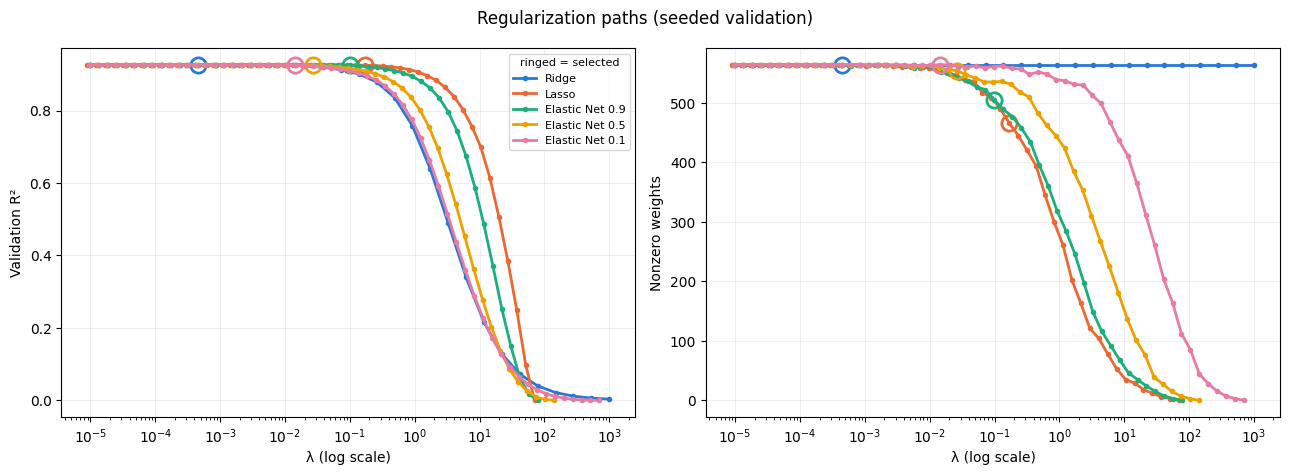

In [28]:
# Selection (rules above); only converged fits are eligible.
chosen = {"Ridge": select(paths["Ridge"], None)}
for label in L1_RATIOS:
    chosen[label] = select(paths[label], SELECT_R2_TOLERANCE)
elastic = [label for label in L1_RATIOS if label.startswith("Elastic Net")]
best_elastic = max(elastic, key=lambda label: (chosen[label]["val_r2"], -chosen[label]["nonzero"]))
final = {"Ridge": chosen["Ridge"], "Lasso": chosen["Lasso"], "Elastic Net": chosen[best_elastic]}

summary = pd.DataFrame(final).T[["lambda", "l1_ratio", "nonzero", "train_r2", "val_r2",
                                 "train_rmse", "val_rmse", "top_decile_shortfall",
                                 "top_predicted_decile_shortfall", "status", "iterations",
                                 "final_max_move"]]
summary.insert(3, "of_features", X4_train.shape[1] - 1)
# Each path must peak inside its grid, not at its last (weakest) lambda.
for label, path in paths.items():
    best = int(path["val_r2"].idxmax())
    print(f"{label}: best validation R2 {path['val_r2'].iloc[best]:.5f} at point {best + 1} "
          f"of {len(path)} (lambda {path['lambda'].iloc[best]:.3g})")
print(f"Elastic Net ratio chosen: {best_elastic}")
print("Every Elastic Net ratio at its selected lambda:")
display(pd.DataFrame({label: chosen[label] for label in elastic}).T[
    ["lambda", "nonzero", "val_r2", "val_rmse", "top_decile_shortfall"]])
print("Selected model per method (validation unless marked train):")
display(summary)
summary.to_csv(config.PHASE4_DIR / "selected_models.csv")

def weights_of(label, row):
    """Weights of the selected fit on its path."""
    position = int(np.flatnonzero(paths[label]["lambda"].to_numpy() == row["lambda"])[0])
    return path_weights[label][position]

final_weights = {"Ridge": weights_of("Ridge", chosen["Ridge"]),
                 "Lasso": weights_of("Lasso", chosen["Lasso"]),
                 "Elastic Net": weights_of(best_elastic, chosen[best_elastic])}
plot_regularization_paths(paths, {label: row["lambda"] for label, row in chosen.items()},
                          "Regularization paths (seeded validation)")
plt.show()

In [29]:
# Column verdicts with the best selected model's settings.
verdict_method = max(final, key=lambda label: final[label]["val_r2"])
v_lambda, v_rho = final[verdict_method]["lambda"], final[verdict_method]["l1_ratio"]
v_weights = final_weights[verdict_method]
v_scores = score_weights(v_weights, X4_train, y_train, X4_val, y_val, decile_edges)
print(f"verdict model: {verdict_method} (lambda {v_lambda:.4g}, rho {v_rho}); "
      f"validation R2 {v_scores['val_r2']:.4f}")

lasso_weights = final_weights["Lasso"]
names = target_design.feature_names
lineage = target_design.lineage
target_groups = list(phase3_artifact["target_groups"])
rows = []
for column in ORIGINAL_COLUMNS:
    terms = [i for i, name in enumerate(names) if column in lineage[name]]
    in_model = len(terms) > 0
    row = {"column": column, "terms_in_target": len(terms),
           "terms_surviving_lasso": int(np.count_nonzero(lasso_weights[terms])) if terms else 0}
    ablation_change = add_back_change = np.nan
    all_dropped = False
    if in_model:  # remove the column and every term derived from it
        ablated = Phase2Features(target_design.phase1, target_groups,
                                 excluded=[column]).fit(train_df)
        _, scores = refit_like(ablated, train_df, y_train, val_df, y_val, names, v_weights,
                               v_lambda, v_rho, STEP4, MAX_ITER4, TOL4, decile_edges)
        ablation_change = scores["val_r2"] - v_scores["val_r2"]
        row.update({"ablation_val_r2_change": ablation_change,
                    "ablation_val_rmse_change": scores["val_rmse"] - v_scores["val_rmse"],
                    "ablation_top_decile_shortfall_change":
                        scores["top_decile_shortfall"] - v_scores["top_decile_shortfall"]})
    if column in ADD_BACK_GROUPS:  # add the column (or its main effect) back
        extended = Phase2Features(target_design.phase1,
                                  target_groups + [ADD_BACK_GROUPS[column]]).fit(train_df)
        added = len(extended.feature_names) - len(names)
        all_dropped = added == 0
        row["add_back_columns_kept"] = added
        if not all_dropped:
            _, scores = refit_like(extended, train_df, y_train, val_df, y_val, names, v_weights,
                                   v_lambda, v_rho, STEP4, MAX_ITER4, TOL4, decile_edges)
            add_back_change = scores["val_r2"] - v_scores["val_r2"]
            row.update({"add_back_val_r2_change": add_back_change,
                        "add_back_val_rmse_change": scores["val_rmse"] - v_scores["val_rmse"]})
    A_train, A_val = alone_design(train_df, val_df, column)
    alone = LinearRegressionGD(STEP4 / largest_curvature(A_train), MAX_ITER4, TOL4).fit(A_train, y_train)
    row["alone_val_r2"] = regression_metrics(y_val, A_val @ alone.weights)["r2"]
    row["verdict"] = verdict(in_model, ablation_change, add_back_change, all_dropped,
                             row["alone_val_r2"], VERDICT_R2_TOLERANCE, ALONE_R2_THRESHOLD)
    rows.append(row)
verdicts = pd.DataFrame(rows)
verdicts.to_csv(config.PHASE4_DIR / "column_verdicts.csv", index=False)
display(verdicts.round(4))

verdict model: Ridge (lambda 0.000452, rho 0.0); validation R2 0.9262


,column,terms_in_target,terms_surviving_lasso,add_back_columns_kept,add_back_val_r2_change,add_back_val_rmse_change,alone_val_r2,verdict,ablation_val_r2_change,ablation_val_rmse_change,ablation_top_decile_shortfall_change
0,instant,0,0,1.0,0.0003,-0.0901,0.0941,redundant,NaN,NaN,NaN
1,dteday,0,0,2.0,0.0002,-0.0785,0.0938,redundant,NaN,NaN,NaN
2,season,69,56,0.0,NaN,NaN,0.0529,redundant,0.0000,-0.0014,-0.0047
3,yr,48,45,NaN,NaN,NaN,0.0671,useful,-0.1103,28.9343,63.1847
4,mnth,195,149,NaN,NaN,NaN,0.0697,useful,-0.0055,1.8309,3.8057
5,hr,537,443,NaN,NaN,NaN,0.4908,useful,-0.5684,97.3310,239.8163
6,holiday,24,18,NaN,NaN,NaN,-0.0003,uninformative,-0.0000,0.0126,-0.0063
7,weekday,121,100,NaN,NaN,NaN,-0.0006,useful,-0.0052,1.7284,3.2561
8,workingday,71,63,0.0,NaN,NaN,0.0001,useful,-0.0162,5.2125,12.4854
9,weathersit,10,9,NaN,NaN,NaN,0.0164,useful,-0.0175,5.6113,5.6632


In [30]:
# Artifact for Phase 5: the features the selected Lasso keeps, with lineage.
survivors = [i for i in range(1, len(names)) if lasso_weights[i] != 0]
surviving_names = [names[i] for i in survivors]
surviving_columns = sorted({c for name in surviving_names for c in lineage[name]})
print(f"Lasso keeps {len(survivors)} of {len(names) - 1} features, "
      f"derived from {len(surviving_columns)} original columns: {surviving_columns}")
group_of = {name: "Phase 1 main effects" for name in target_design.phase1.feature_names}
group_of.update({term_name(term): group for group, term in target_design._group_terms()})
kept_by_group = (pd.DataFrame({"group": [group_of[n] for n in names[1:]],
                               "kept": [lasso_weights[i] != 0 for i in range(1, len(names))]})
                 .groupby("group", sort=False)["kept"].agg(terms="size", kept="sum"))
display(kept_by_group)

save_phase4_artifact(config.PHASE4_ARTIFACT, {
    "selected": {label: {"lambda": float(row["lambda"]), "l1_ratio": float(row["l1_ratio"]),
                         **{k: row[k] for k in ("nonzero", "train_r2", "val_r2", "val_rmse",
                                                "top_decile_shortfall",
                                                "top_predicted_decile_shortfall", "status",
                                                "iterations")},
                         "weights": final_weights[label].tolist()}
                 for label, row in final.items()},
    "elastic_net_ratio": float(final["Elastic Net"]["l1_ratio"]),
    "verdict_method": verdict_method,
    "lasso_surviving_features": [{"index": i, "name": names[i], "lineage": lineage[names[i]]}
                                 for i in survivors],
    "lasso_surviving_original_columns": surviving_columns,
    "column_verdicts": verdicts.to_dict(orient="records"),
    "rules": {"select_r2_tolerance": SELECT_R2_TOLERANCE,
              "verdict_r2_tolerance": VERDICT_R2_TOLERANCE,
              "alone_r2_threshold": ALONE_R2_THRESHOLD,
              "grid_sizes": {label: len(grid) for label, (_, grid) in grids.items()},
              "lambda_floor": LAMBDA_FLOOR},
    "settings": {"seed": seed, "step_multiplier": STEP4, "max_iter": MAX_ITER4, "tol": TOL4},
    "features": target_design.to_dict(),
})
print("Saved for Phase 5:", config.PHASE4_ARTIFACT.relative_to(config.ROOT))

Lasso keeps 466 of 564 features, derived from 11 original columns: ['holiday', 'hr', 'hum', 'mnth', 'season', 'temp', 'weathersit', 'weekday', 'windspeed', 'workingday', 'yr']


,terms,kept
group,,
Phase 1 main effects,47,44
hour x workingday,23,22
hour x yr,23,23
hour x season,69,56
hour-block x weathersit,8,8
temp x hum,1,1
hour x workingday x yr,24,21
hour x workingday x temp,47,40
hour x holiday,23,18


Saved for Phase 5: experiments\phase4\phase4_artifact.json


### Outcome

_DRAFT — team to review._

**Grid revision.** In the first run all four L1-type paths peaked at their last λ. We extended them down to 1e-5 at the same spacing and re-ran.
- The first 30 points of every path reproduced exactly.
- Ridge, Lasso and every column verdict stayed the same. Only Elastic Net's choice moved, from ρ = 0.5 to ρ = 0.1.
- The numbers below are from the revised run.

1. **Accuracy: right.**
   - Ridge was best: R² 0.926237 at λ = 0.00045, against 0.926228 unpenalized.
   - Lasso (λ 0.169) scored 0.9248 and Elastic Net (ρ 0.1, λ 0.0144) 0.9246.
   - **Lesson:** Phase 3 left no variance to remove, so regularization only paid bias. The more the penalty bit, the lower R² went.
2. **Sparsity.**
   - *(a) Count: right.* Lasso kept 466 of 564 terms.
   - *(b) Which groups go first: mostly wrong.* No group was emptied. temp × hum survived. hour × holiday kept 18 of its 23 terms. Only hour × month behaved as we said: it was pruned most, keeping 138 of 184.
3. **Busiest hours: right.** The top-decile shortfall rose from 53.8 bikes unpenalized to 56.9 under Lasso and 57.6 under Elastic Net. By predicted demand it rose from 41.2 to 43.2 and 43.9. Ridge's tiny λ left it unchanged (54.0 and 41.2).
4. **Column verdicts.**
   - atemp: redundant, as expected (adding it back: +0.0003 R²).
   - workingday: useful, as expected. Removing it costs 0.0162 R² and 12.5 bikes of peak shortfall, although on its own it explains almost nothing (R² 0.0001).
   - windspeed: **redundant, not uninformative**, so we were narrowly wrong. Removing it costs only 0.0006, but on its own it reaches R² 0.0146, just above the 0.01 threshold: a weak signal the weather and season columns already carry.
   - instant: redundant, as expected (+0.0003).
   - Overall: useful: hr, yr, weathersit, workingday, temp, mnth, weekday. Redundant: season (hour × month carries it exactly), hum, windspeed, atemp, instant, dteday. Uninformative: holiday.

**Lesson (holiday).** Lasso kept 18 of holiday's 24 terms, yet removing all of them cost nothing (−0.0000 R²). A surviving Lasso coefficient is not evidence of usefulness; a zero would be evidence of non-usefulness.

**Handed to Phase 5:** the 466 Lasso-surviving features from 11 original columns, with lineage and the fitted scaler. Ridge is the recommended regression model for the submission (`experiments/phase4/phase4_artifact.json`).

## Phase 5 — Logistic Regression

### Phase 5 plan: label, features, model, cutoff

**Label: what "high demand" means.** An hour is high demand (1) if its `cnt` exceeds the 75th percentile of *training* hours in the same **hour × working-day × year** group (96 groups). The cutoffs come from the training portion only. Validation hours are looked up in that same table, and nothing is recomputed from validation.

Why this definition (numbers in the cell below, training rows only):
- *A single global cutoff mostly teaches the model the clock.* Night hours are never above it and commute peaks nearly always are. The classifier could score well just by reading the hour, and some hours would have one class only (perfect separation, so the logistic weights would grow without bound).
- *A cutoff per hour × working day but not per year mostly labels "is it 2012".* Demand grew between the years, so most 2012 hours would be "high" and most 2011 hours not.
- *Per hour × working day × year*, every kind of hour has about a quarter of its hours labelled high. The label then means "unusually busy for this hour, day type and year": the hours that drain stations the operator would otherwise have stocked for a normal day. Small groups and tied counts move a group's share a little either way.

**Features: exactly Phase 4's Lasso survivors** (selected Lasso after the grid-extension rerun), with the same fitted encoder and scaler and lineage from the Phase 4 artifact. Neither `cnt` nor the group cutoffs ever enter X.

**Model.** $p = \sigma(Xw)$ with $\sigma(z) = 1/(1 + e^{-z})$. We minimize the log-loss $-\frac{1}{m}\sum[y\log p + (1-y)\log(1-p)]$, whose gradient is $X^\top(p - y)/m$, with our own gradient descent loop.
- *Explicit gradient.* $p$ changes at every step, so there is no fixed table of sums as for the squared error.
- *Learning rate from curvature.* The log-loss curvature is $X^\top \mathrm{diag}(p(1-p))X/m$, and $p(1-p) \le 1/4$, so it is at most $L = \lambda_{max}(X^\top X/m)/4$. Gradient descent never increases the loss for any step below $2/L = 8/\lambda_{max}$. We keep the rule used throughout, $1.9/L$.
- *Same stopping rule as before:* max |gradient| < 1e-4, cap 50,000 updates, divergence check. Convergence is reported.

**Probability cutoff.** We pick the cutoff with the best validation F1, searching 0.05–0.95 in steps of 0.01, and show 0.5 for comparison. Choosing the cutoff and scoring it on the same validation set is slightly optimistic: the F1 at the tuned cutoff is a little better than a fresh set would give. ROC-AUC does not depend on the cutoff.

**Report.** Confusion matrix; accuracy next to the always-0 baseline; precision, recall, F1, ROC-AUC; class balance in training and validation. The largest coefficients are read as odds ratios $e^{\beta}$. Each feature is standardized, so $e^{\beta}$ is the factor by which the odds of "high demand" change when that column rises by one standard deviation, all others held fixed.

In [31]:
from src.phase4_regularization import load_phase4_artifact
from src.phase5_logistic import (
    GROUP_COLUMNS,
    LogisticRegressionGD,
    best_f1_threshold,
    classification_scores,
    high_demand_cutoffs,
    high_demand_labels,
    label_definition_comparison,
    logistic_curvature_bound,
    save_phase5_artifact,
    threshold_scan,
)
from src.visualization import INK, SERIES_COLORS

# Why the label is contextual and includes year (training rows only).
display(label_definition_comparison(train_df).round(3))

# The chosen label: cutoffs from training rows only.
cutoffs = high_demand_cutoffs(train_df)
label_train = high_demand_labels(train_df, cutoffs)
group_positives = (train_df[GROUP_COLUMNS].assign(high=label_train)
                   .groupby(GROUP_COLUMNS)["high"].agg(rows="size", positive_rate="mean")
                   .join(cutoffs))
print(f"training positives: {label_train.sum()} of {len(label_train)} "
      f"({label_train.mean():.1%}) across {len(cutoffs)} groups")
print("group positive rate: min {:.1%}, median {:.1%}, max {:.1%}".format(
    *group_positives["positive_rate"].quantile([0, 0.5, 1])))
display(group_positives.sort_values("positive_rate").round(3))

,definition,positive_rate,rate_2011,rate_2012,hours_never_positive,hours_always_positive,lowest_hourly_rate,highest_hourly_rate
0,global cutoff,0.250,0.156,0.343,8,0,0.000,0.752
1,hour x working day,0.245,0.056,0.431,0,0,0.212,0.252
2,hour x working day x year (chosen),0.244,0.243,0.246,0,0,0.205,0.254


training positives: 2127 of 8708 (24.4%) across 96 groups
group positive rate: min 19.1%, median 25.0%, max 26.0%


rows  positive_rate  cutoff
hr workingday yr                             
3  1          0    110          0.191    6.00
              1    122          0.197    7.00
4  1          1    121          0.207    9.00
3  0          0     53          0.208   30.00
4  1          0    109          0.211    6.00
...                ...            ...     ...
13 0          0     58          0.259  372.25
16 0          0     58          0.259  383.25
17 0          0     58          0.259  357.75
21 0          1     54          0.259  227.50
2  0          0     50          0.260   59.75

[96 rows x 3 columns]

### Expectation

_Written before the official run._

1. **Separability.** The label removes each hour × working-day × year group's normal level by design, so the clock and calendar cannot predict it on their own. What remains is mainly weather: rain versus sun, temperature, humidity. We expect this to explain most of the "busier than usual" surprises, giving a good ROC-AUC of roughly 0.8–0.9, with accuracy clearly above the 75% always-0 baseline.

2. **Cutoff.** We expect the best-F1 probability cutoff to land above 0.5, favouring precision (fewer false alarms) over recall (fewer missed surges).

3. **Largest odds ratios.** Weather and temperature features should dominate. Hour dummies should matter little, since the label already removes each slot's normal level.

4. **Weakest recall: night hours.** Counts there are tiny and often tied at the cutoff, so a "surge" at 3am is mostly noise that no feature can predict.

466 Lasso-surviving features (+ intercept); class balance: training 24.4% high, validation 25.2% high
log-loss curvature at most L = 1.0424; safe below 2/L = 1.919; learning rate 1.9/L = 1.823


converged after 1229 updates; final max|gradient| 1.00e-04; loss ever increased: False; final training log-loss 0.3331


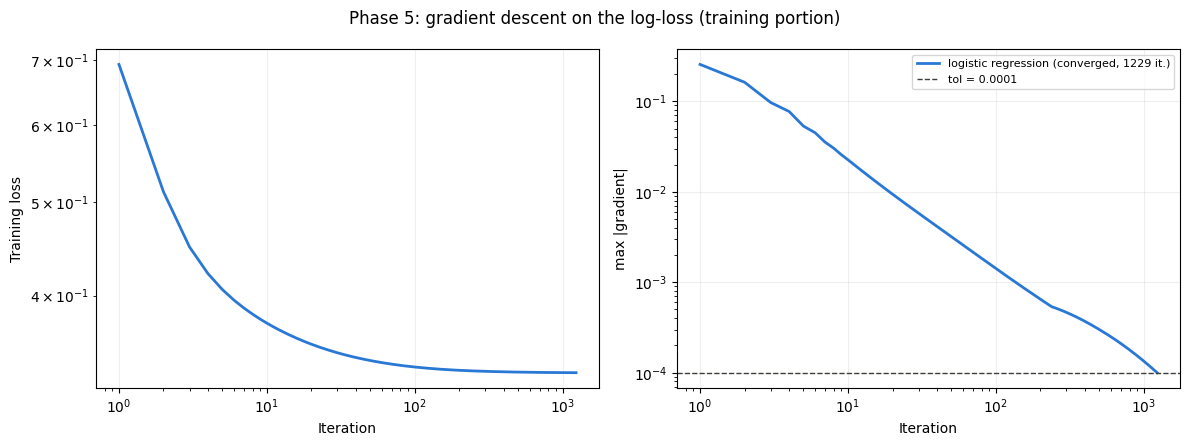

In [32]:
# Features: exactly Phase 4's Lasso survivors, same fitted encoder and scaler.
phase4_artifact = load_phase4_artifact(config.PHASE4_ARTIFACT)
survivors = phase4_artifact["lasso_surviving_features"]
phase5_columns = [0] + [feature["index"] for feature in survivors]  # intercept + survivors
phase5_design = Phase2Features.from_dict(phase4_artifact["features"])
X5_train = phase5_design.transform(train_df)[:, phase5_columns]
X5_val = phase5_design.transform(val_df)[:, phase5_columns]
phase5_names = [phase5_design.feature_names[i] for i in phase5_columns]
assert phase5_names[1:] == [feature["name"] for feature in survivors]
label_val = high_demand_labels(val_df, cutoffs)
print(f"{len(survivors)} Lasso-surviving features (+ intercept); "
      f"class balance: training {label_train.mean():.1%} high, "
      f"validation {label_val.mean():.1%} high")

# Learning rate from the curvature bound: L = lambda_max / 4, step 1.9 / L.
curvature5 = logistic_curvature_bound(X5_train)
step5 = 1.9 / curvature5
print(f"log-loss curvature at most L = {curvature5:.4f}; safe below 2/L = {2 / curvature5:.3f}; "
      f"learning rate 1.9/L = {step5:.3f}")
classifier = LogisticRegressionGD(learning_rate=step5, max_iter=MAX_ITER4, tol=TOL4)
classifier_result = classifier.fit(X5_train, label_train.astype(float))
print(f"{classifier_result.status} after {classifier_result.iterations} updates; "
      f"final max|gradient| {classifier_result.grad_history[-1]:.2e}; loss ever increased: "
      f"{bool(np.any(np.diff(classifier_result.loss_history) > 1e-12))}; "
      f"final training log-loss {classifier_result.loss_history[-1]:.4f}")
plot_gd_runs({"logistic regression": classifier_result}, TOL4,
             "Phase 5: gradient descent on the log-loss (training portion)")
plt.show()

Validation (the tuned cutoff is chosen and scored on the same set: slightly optimistic)


,threshold,tp,fp,fn,tn,accuracy,precision,recall,f1,roc_auc,always_0_accuracy
tuned cutoff 0.37,0.37,388,230,161,1399,0.8205,0.6278,0.7067,0.6650,0.8709,0.7479
cutoff 0.50,0.50,309,137,240,1492,0.8269,0.6928,0.5628,0.6211,0.8709,0.7479


tuned cutoff 0.37: confusion matrix (rows = actual 0/1, columns = predicted 0/1)


,predicted 0,predicted 1
actual 0,1399.0,230.0
actual 1,161.0,388.0


cutoff 0.50: confusion matrix (rows = actual 0/1, columns = predicted 0/1)


,predicted 0,predicted 1
actual 0,1492.0,137.0
actual 1,240.0,309.0


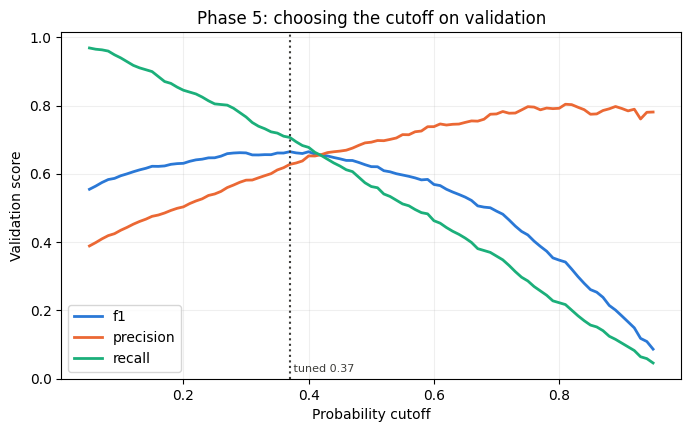

In [33]:
# Probability cutoff: best validation F1 over 0.05-0.95, and 0.5 for comparison.
prob_val = classifier.predict_proba(X5_val)
scan = threshold_scan(label_val, prob_val, np.round(np.arange(0.05, 0.951, 0.01), 2))
chosen_threshold = best_f1_threshold(scan)
results5 = pd.DataFrame([classification_scores(label_val, prob_val, chosen_threshold),
                         classification_scores(label_val, prob_val, 0.5)],
                        index=[f"tuned cutoff {chosen_threshold:.2f}", "cutoff 0.50"])
print("Validation (the tuned cutoff is chosen and scored on the same set: slightly optimistic)")
display(results5.round(4))
for name, row in results5.iterrows():
    print(f"{name}: confusion matrix (rows = actual 0/1, columns = predicted 0/1)")
    display(pd.DataFrame([[row["tn"], row["fp"]], [row["fn"], row["tp"]]],
                         index=["actual 0", "actual 1"], columns=["predicted 0", "predicted 1"]))

fig, ax = plt.subplots(figsize=(8, 4.5))
for color, column in zip(SERIES_COLORS, ("f1", "precision", "recall")):
    ax.plot(scan["threshold"], scan[column], color=color, lw=2, label=column)
ax.axvline(chosen_threshold, color=INK, ls=":", lw=1.5)
ax.text(chosen_threshold, 0.02, f" tuned {chosen_threshold:.2f}", fontsize=8, color=INK)
ax.set_xlabel("Probability cutoff")
ax.set_ylabel("Validation score")
ax.set_title("Phase 5: choosing the cutoff on validation")
ax.grid(alpha=0.2)
ax.legend()
plt.show()

In [34]:
# Largest coefficients as odds ratios: e^beta = change in the odds of "high
# demand" when that (standardized) column rises by one standard deviation.
lineage5 = phase5_design.lineage
coefficients5 = pd.DataFrame({
    "feature": phase5_names[1:],
    "from columns": [", ".join(lineage5[name]) for name in phase5_names[1:]],
    "beta": classifier.weights[1:],
})
coefficients5["odds_ratio_per_sd"] = np.exp(coefficients5["beta"])
largest = coefficients5.reindex(coefficients5["beta"].abs().sort_values(ascending=False).index)
print(f"intercept {classifier.weights[0]:.3f}: odds of 'high' for an average hour "
      f"= {np.exp(classifier.weights[0]):.3f}")
display(largest.head(15).round(3))

intercept -2.754: odds of 'high' for an average hour = 0.064


,feature,from columns,beta,odds_ratio_per_sd
1,temp,temp,1.295,3.652
40,mnth=9,mnth,1.055,2.871
41,mnth=10,mnth,0.961,2.615
36,mnth=5,mnth,0.929,2.532
37,mnth=6,mnth,0.921,2.511
38,mnth=7,mnth,0.881,2.414
39,mnth=8,mnth,0.835,2.305
27,weekday=1,weekday,-0.714,0.490
33,mnth=2,mnth,-0.702,0.496
42,mnth=11,mnth,0.651,1.917


In [35]:
# Operator check: which busy hours does the classifier miss? Recall and
# precision at the tuned cutoff by day part and day type (validation).
predicted_val = (prob_val >= chosen_threshold).astype(int)
day_part = pd.cut(val_df["hr"], [-1, 5, 9, 15, 19, 23],
                  labels=["night 0-5", "morning 6-9", "midday 10-15", "evening 16-19", "late 20-23"])
checks = pd.DataFrame({"day part": day_part.to_numpy(), "workingday": val_df["workingday"].to_numpy(),
                       "actual": label_val, "predicted": predicted_val})
def part_scores(group):
    tp = ((group["actual"] == 1) & (group["predicted"] == 1)).sum()
    return pd.Series({"hours": len(group), "high_hours": group["actual"].sum(),
                      "recall": tp / max(group["actual"].sum(), 1),
                      "precision": tp / max(group["predicted"].sum(), 1)})
display(checks.groupby(["workingday", "day part"], observed=True)[["actual", "predicted"]]
        .apply(part_scores).round(3))

hours  high_hours  recall  precision
workingday day part                                           
0          evening 16-19  119.0        33.0   0.697      0.697
           late 20-23     106.0        28.0   0.857      0.774
           midday 10-15   156.0        44.0   0.659      0.558
           morning 6-9    129.0        32.0   0.781      0.658
           night 0-5      185.0        53.0   0.585      0.544
1          evening 16-19  282.0        77.0   0.831      0.667
           late 20-23     227.0        54.0   0.907      0.690
           midday 10-15   371.0        88.0   0.659      0.617
           morning 6-9    264.0        61.0   0.689      0.618
           night 0-5      339.0        79.0   0.544      0.551

In [36]:
# Diagnostic: how much of the ROC-AUC does the calendar alone explain? (validation)
from sklearn.metrics import roc_auc_score

print("training share of 'high' hours by month (%):",
      (pd.Series(label_train).groupby(train_df["mnth"].to_numpy()).mean() * 100).round(1).to_dict())

# 1. Calendar only, no model: each validation hour is scored by the training
#    share of 'high' hours in its month x weekday.
calendar_rate = (train_df.assign(high=label_train)
                 .groupby(["mnth", "weekday"])["high"].mean().rename("calendar_score"))
calendar_score = val_df.join(calendar_rate, on=["mnth", "weekday"])["calendar_score"].to_numpy()
auc_classifier = roc_auc_score(label_val, prob_val)
auc_calendar = roc_auc_score(label_val, calendar_score)
print(f"ROC-AUC: classifier {auc_classifier:.3f} | calendar only (month x weekday) {auc_calendar:.3f}")

# 2. The classifier inside one month or one season, where the calendar cannot help.
def auc_within(column):
    rows = []
    for value in sorted(val_df[column].unique()):
        mask = (val_df[column] == value).to_numpy()
        both_classes = 0 < label_val[mask].sum() < mask.sum()
        rows.append({column: value, "hours": int(mask.sum()),
                     "positive_rate": label_val[mask].mean(),
                     "roc_auc": roc_auc_score(label_val[mask], prob_val[mask])
                                if both_classes else np.nan})
    return pd.DataFrame(rows)

auc_by_month, auc_by_season = auc_within("mnth"), auc_within("season")
print(f"ROC-AUC within a month, averaged over months: {auc_by_month['roc_auc'].mean():.3f}")
print(f"ROC-AUC within a season: {auc_by_season['roc_auc'].min():.3f} to "
      f"{auc_by_season['roc_auc'].max():.3f}")
display(auc_by_season.round(3))

training share of 'high' hours by month (%): {1: 0.4, 2: 0.6, 3: 4.0, 4: 12.0, 5: 32.1, 6: 48.8, 7: 45.1, 8: 44.0, 9: 45.5, 10: 39.0, 11: 14.4, 12: 6.7}
ROC-AUC: classifier 0.871 | calendar only (month x weekday) 0.809
ROC-AUC within a month, averaged over months: 0.747
ROC-AUC within a season: 0.641 to 0.862


,season,hours,positive_rate,roc_auc
0,1,537,0.011,0.641
1,2,572,0.306,0.839
2,3,551,0.446,0.742
3,4,518,0.236,0.862


**What the diagnostic shows.** The label removes each hour × working-day × year group's normal level, but not the season. In the training rows only 0.4% of January hours are "high", against 48.8% of June hours. The label therefore still carries seasonality: part of "unusually busy for this slot and year" simply means "it is summer".

- A ranking that uses only the calendar (month × weekday), with no model, already reaches ROC-AUC **0.809**, against the classifier's **0.871**.
- The classifier's real added skill shows where the calendar cannot help. Ranking hours *within* a single month gives an average ROC-AUC of **0.747**. Within a season it ranges from **0.641** (winter, where only 1.1% of validation hours are positive) to **0.862** (autumn). Temperature, weather and the remaining calendar terms still separate busy from normal hours there, but less well than the headline number suggests.

The headline ROC-AUC should therefore be read together with these two numbers, not alone.

In [37]:
# Final classifier artifact.
config.PHASE5_DIR.mkdir(parents=True, exist_ok=True)
tuned = results5.iloc[0]
save_phase5_artifact(config.PHASE5_ARTIFACT, {
    "label": {"groups": GROUP_COLUMNS, "quantile": 0.75,
              "cutoffs": [{"hr": int(h), "workingday": int(w), "yr": int(y), "cutoff": float(c)}
                          for (h, w, y), c in cutoffs.items()]},
    "features": phase5_names, "weights": classifier.weights.tolist(),
    "learning_rate": step5, "iterations": classifier_result.iterations,
    "status": classifier_result.status, "threshold": chosen_threshold,
    "validation": results5.to_dict(orient="index"),
})
print("Saved:", config.PHASE5_ARTIFACT.relative_to(config.ROOT))

Saved: experiments\phase5\phase5_artifact.json


### Pipeline retrospective

_DRAFT — team to review._

**Phases 1–2.**
- Phase 1 fitted 47 main effects with our own gradient descent (learning rate 1.9/λ_max, 267 updates) and reached validation R² 0.682. It underfit, missing the busiest hours by 177 bikes on average.
- Its residuals showed what was missing: 44% of their variance lay between hour × working-day groups.
- Its weights became Phase 2's starting point. Phase 2 added interaction groups chosen from those residuals one at a time, each step warm-started from the Phase 1 weights. Degree 3 (242 features) reached 0.9225 and cut the busiest-hour shortfall by two thirds.

**Phase 3.**
- Taking Phase 2's design and order, it extended the sweep beyond it and found no overfitting before degree 4.
- Its pre-registered rule moved the target to 564 features (seeded R² 0.9262).
- The chronological split showed the realistic cost of forecasting a later, busier period: R² 0.9224, and peak shortfalls about 10 bikes larger.

**Phase 4.**
- It found almost no variance left to remove. Ridge at a tiny λ matched the unpenalized model; Lasso kept 466 of the 564 terms at a small cost in R² and in peak shortfall.
- Its column verdicts named hr, yr, workingday, weathersit, temp, month and weekday as useful.

**Phase 5 and the side analyses.**
- Phase 5 used exactly those 466 features to flag unusually busy hours (ROC-AUC 0.871, F1 0.665) and showed that much of that skill is the season still contained in its label.
- The asymmetric-cost bonus ran beside Phase 1 (and again on Phase 2's features) without feeding the chain.
- The final submission comes from Phase 4's Ridge, refitted on all labeled rows.

The table collects each phase's key numbers from the artifact it saved.

In [38]:
# Pipeline retrospective: each phase's key numbers, read from the artifacts it saved.
p1 = load_phase1_artifact(config.PHASE1_ARTIFACT)
p2 = load_phase2_artifact(config.PHASE2_ARTIFACT)
p3 = load_phase3_artifact(config.PHASE3_ARTIFACT)
p4 = load_phase4_artifact(config.PHASE4_ARTIFACT)
retrospective = pd.DataFrame([
    {"phase": "1 Gradient descent", "consumes": "seeded split",
     "key choice": f"47 main effects, learning rate {p1['learning_rate']:.3f}, "
                   f"{p1['iterations']} updates",
     "validation": f"R2 {p1['metrics']['validation']['r2']:.4f}, RMSE {p1['metrics']['validation']['rmse']:.1f}"},
    {"phase": "2 Polynomial", "consumes": "Phase 1 weights (warm start)",
     "key choice": f"degree {p2['degree']}, {len(p2['feature_names']) - 1} features",
     "validation": f"R2 {p2['metrics']['val_r2']:.4f}, RMSE {p2['metrics']['val_rmse']:.1f}"},
    {"phase": "3 Bias-variance", "consumes": "Phase 2 design and order",
     "key choice": f"target up to {p3['target_step']}, {len(p3['feature_names']) - 1} features",
     "validation": f"seeded R2 {p3['diagnosis']['target_val_r2']['seeded']:.4f}, "
                   f"chronological R2 {p3['diagnosis']['target_val_r2']['chronological']:.4f}"},
    *[{"phase": f"4 {label}", "consumes": "Phase 3 target design",
       "key choice": f"lambda {model['lambda']:.3g}, rho {model['l1_ratio']}, "
                     f"{int(model['nonzero'])} nonzero",
       "validation": f"R2 {model['val_r2']:.4f}, RMSE {model['val_rmse']:.1f}"}
      for label, model in p4["selected"].items()],
    {"phase": "5 Logistic", "consumes": f"{len(survivors)} Lasso survivors",
     "key choice": f"contextual label, cutoff {chosen_threshold:.2f}",
     "validation": f"F1 {tuned['f1']:.3f}, ROC-AUC {tuned['roc_auc']:.3f}, "
                   f"accuracy {tuned['accuracy']:.3f} (always-0 {tuned['always_0_accuracy']:.3f})"},
])
display(retrospective)

,phase,consumes,key choice,validation
0,1 Gradient descent,seeded split,"47 main effects, learning rate 0.955, 267 updates","R2 0.6823, RMSE 103.6"
1,2 Polynomial,Phase 1 weights (warm start),"degree 3, 242 features","R2 0.9225, RMSE 51.1"
2,3 Bias-variance,Phase 2 design and order,"target up to hour x month, 564 features","seeded R2 0.9262, chronological R2 0.9224"
3,4 Ridge,Phase 3 target design,"lambda 0.000452, rho 0.0, 564 nonzero","R2 0.9262, RMSE 49.9"
4,4 Lasso,Phase 3 target design,"lambda 0.169, rho 1.0, 466 nonzero","R2 0.9248, RMSE 50.4"
5,4 Elastic Net,Phase 3 target design,"lambda 0.0144, rho 0.1, 564 nonzero","R2 0.9246, RMSE 50.5"
6,5 Logistic,466 Lasso survivors,"contextual label, cutoff 0.37","F1 0.665, ROC-AUC 0.871, accuracy 0.820 (alway..."


### Outcome

_DRAFT — team to review._

1. **Separability: the numbers were right, the reason was wrong.**
   - ROC-AUC 0.871. Accuracy 0.820 at the tuned cutoff, against 0.748 for always predicting "not high".
   - But the calendar *does* predict the label. The label still carries seasonality: 0.4% of January training hours are "high", against 48.8% of June hours.
   - A calendar-only ranking reaches ROC-AUC 0.809. Within a single month the classifier ranks at 0.747, and within a season at 0.641–0.862. That within-month skill is its real contribution beyond the calendar.
2. **Cutoff: wrong.** Best F1 came at **0.37**, favouring recall (0.707) over precision (0.628), F1 0.665. At 0.5: precision 0.693, recall 0.563, F1 0.621.
   - **Lesson:** moving to 0.5, accuracy *rose* (0.820 → 0.827) while F1 *fell*.
   - The higher cutoff turned 79 caught busy hours into misses (388 → 309 true positives) and saved 93 false alarms (230 → 137). Accuracy counts both kinds of error equally.
   - With 25% positives, predicting "not high" is usually right; always-0 already scores 0.748. Accuracy therefore rewards missing busy hours, which is exactly the operator's costly error.
3. **Odds ratios: half right.**
   - Temperature is the largest effect (×3.65 odds per standard deviation), and the hour dummies matter little (only 20:00, ×0.63).
   - But months dominate the rest: September ×2.87, October ×2.62, May–August ×2.3–2.5, February ×0.50. Monday–Wednesday are ×0.49–0.60 against Sunday. That is the seasonal and weekly pattern inside the label. Humidity is ×0.65.
4. **Night recall weakest: right.** Night recall is 0.585 on non-working days and 0.544 on working days, against 0.659–0.907 for the other day parts.

**For the operator.** At the tuned cutoff the classifier flags about 7 of every 10 unusually busy hours, and about 6 of every 10 alarms are real.

**Saved:** the classifier weights, cutoff 0.37 and the 96 label cutoffs (`experiments/phase5/phase5_artifact.json`).

## Final model and test predictions

**Model:** Phase 4's recommended regression model, Ridge (λ = 0.00045), on Phase 3's 564-feature design. It has the best seeded validation R² of the three methods. The submission must come from the regression pipeline, not from the Phase 5 classifier.

**Why refit on train + validation.** Every choice was frozen on the seeded split before this step: the features, the interaction groups, the degree, the target design, the penalty and λ, and the GD procedure. The validation rows have done their job of choosing and checking. Refitting on all 10,886 labeled rows changes none of those choices; it only gives the same model 25% more training data. In Phase 3's learning curves, validation error kept falling, slowly, as training rows were added. Everything that is fitted to data is refitted on the combined rows only: encoder levels, scaler, centering means and weights. `test.csv` is used only to predict, never to fit or tune. Predictions below zero are clipped to 0 (rentals cannot be negative; for a nonnegative target, clipping can only reduce squared error). The rows keep the sample file's `instant` order.

In [39]:
from src.phase4_regularization import PenalizedGD, penalized_learning_rate

# Phase 4's recommended model: Ridge at its selected lambda.
ridge = phase4_artifact["selected"]["Ridge"]
assert ridge["l1_ratio"] == 0.0
final_lambda = ridge["lambda"]

# Refit everything on all labeled rows: encoder, scaler, centering means, weights.
y_all = train_all[config.TARGET].to_numpy(dtype=float)
final_phase1 = Phase1Features(seasonal=phase1_state["seasonal"],
                              use_trend=phase1_state["use_trend"]).fit(train_all)
final_design = Phase2Features(final_phase1, list(phase3_artifact["target_groups"])).fit(train_all)
X_all, X_test = final_design.transform(train_all), final_design.transform(test_X)
print(f"{len(train_all)} labeled rows; {X_all.shape[1] - 1} features "
      f"({len(final_design.dropped)} exact combinations dropped); same feature list as the "
      f"seeded-split design: {final_design.feature_names == target_design.feature_names}")

# Same GD procedure as Phase 4: the Ridge path from its largest lambda down to the
# selected one, each fit starting from the previous fit's weights.
ridge_grid = grids["Ridge"][1]
stop = int(np.flatnonzero(np.isclose(ridge_grid, final_lambda, rtol=1e-12, atol=0))[0])
curvature_all = largest_curvature(X_all)
final_weights_all = np.zeros(X_all.shape[1])
final_weights_all[0] = y_all.mean()
for lam in ridge_grid[: stop + 1]:
    final_fit = PenalizedGD(lam, 0.0, penalized_learning_rate(curvature_all, lam, 0.0, STEP4),
                            MAX_ITER4, TOL4).fit(X_all, y_all, init_weights=final_weights_all)
    assert final_fit.converged, f"Ridge refit did not converge at lambda {lam}"
    final_weights_all = final_fit.weights
fit_scores = regression_metrics(y_all, X_all @ final_weights_all)
print(f"final fit (lambda {final_lambda:.3g}): {final_fit.status} after {final_fit.iterations} "
      f"updates, final max|gradient| {final_fit.grad_history[-1]:.2e}; "
      f"training R2 {fit_scores['r2']:.4f}, RMSE {fit_scores['rmse']:.2f} on all labeled rows")

# Predict test.csv, clip below zero, write in the sample file's format and order.
raw_test = X_test @ final_weights_all
sample = pd.read_csv(config.SAMPLE_SUBMISSION_PATH)
assert list(sample.columns) == ["instant", "cnt"]
assert list(sample["instant"]) == list(test_X["instant"]), "test rows must follow the sample order"
submission = sample[["instant"]].assign(cnt=np.clip(raw_test, 0, None))
assert len(submission) == 574 and np.isfinite(submission["cnt"]).all()
assert (submission["cnt"] >= 0).all() and submission["instant"].is_unique
config.SUBMISSION_PATH.parent.mkdir(parents=True, exist_ok=True)
submission.to_csv(config.SUBMISSION_PATH, index=False)
print(f"{len(submission)} predictions; {int(np.sum(raw_test < 0))} below zero clipped to 0; "
      f"min {submission['cnt'].min():.1f}, mean {submission['cnt'].mean():.1f}, "
      f"max {submission['cnt'].max():.1f}")
print("Saved:", config.SUBMISSION_PATH.relative_to(config.ROOT))

10886 labeled rows; 564 features (92 exact combinations dropped); same feature list as the seeded-split design: True


final fit (lambda 0.000452): converged after 2053 updates, final max|gradient| 1.00e-04; training R2 0.9317, RMSE 47.34 on all labeled rows
574 predictions; 35 below zero clipped to 0; min 0.0, mean 191.8, max 870.9
Saved: outputs\submission\sample_submission.csv
